# Лабораторна робота №2

## Порівняння традиційних ML-алгоритмів для задачі класифікації

**Дисципліна:** Методологія та процеси моделювання у штучному інтелекті

**Виконав:** Колодійчук Олександр, ст. гр. КНСШ-13

---

**Датасет:** Rain in Australia (weatherAUS), [Kaggle](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package)
Первинне джерело – Australian Bureau of Meteorology.

**Задача:** бінарна класифікація – прогноз опадів на наступну добу (`RainTomorrow`).

Набір даних та весь конвеєр його підготовки взято з лабораторної роботи №1.
Там же експериментально обґрунтовано кожне рішення: механізм пропусків MNAR,
вибір IterativeImputer (MICE) за чотирма критеріями, Yeo-Johnson замість Box-Cox,
Target Encoding із крос-фітингом та хронологічний поділ вибірки.

### Структура ноутбука

| Розділ | Зміст | Пункт методички |
|---|---|---|
| **0** | Підготовка середовища | – |
| **1** | Дані та сценарії підготовки (А, Б, Б+, В) | 1, 3 |
| **2** | Моделі та протокол оцінювання | 2, 4 |
| **3** | Порівняльні експерименти | 3, 4 |
| **4** | Сильні та слабкі сторони алгоритмів | 5 |
| **5** | Аугментація та перенавчання | 6 |
| **6** | Підсумковий звіт і збереження артефактів | 6 |

Повне виконання ноутбука в Google Colab займає близько 20-25 хвилин.

### Сценарії підготовки даних

| Сценарій | Зміст | Пункт методички |
|---|---|---|
| **А** | Базові дані: мінімальне очищення | 3.1 |
| **Б** | Повноцінно очищені: імп'ютація + кодування + трансформація | 3.2 |
| **Б+** | Очищені + інженерія ознак (повний результат ЛР №1) | додатково |
| **В-SMOTE** | Очищені + SMOTE | 3.3 |
| **В-ADASYN** | Очищені + ADASYN | 3.3 |


---
# Розділ 0. Підготовка середовища

### Комірка 0.1 – встановлення відсутніх бібліотек

Перевіряємо наявність `imbalanced-learn` (реалізації SMOTE та ADASYN) і встановлюємо
лише за потреби. Решта бібліотек присутні у стандартному образі Google Colab.

In [1]:
# --- Перевірка та встановлення залежностей ---
# Встановлюємо пакет тільки якщо його немає: це економить час при повторних запусках.
import importlib.util
import subprocess
import sys

for pkg, module in [("imbalanced-learn", "imblearn")]:
    if importlib.util.find_spec(module) is None:
        print(f"Встановлення {pkg} …")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
    else:
        print(f"{pkg}: вже встановлено")


imbalanced-learn: вже встановлено


### Комірка 0.2 – імпорт бібліотек та глобальні константи

Фіксуємо `RANDOM_STATE = 42` – те саме значення, що й у ЛР №1. Усі випадкові процеси
(поділ вибірки, ініціалізація моделей, SMOTE, ADASYN, підвибірки) використовують його,
що гарантує **відтворюваність** результатів при повторному запуску.

In [2]:
# ========== Стандартні бібліотеки ==========
import time
import warnings
from pathlib import Path

# ========== Робота з даними ==========
import numpy as np
import pandas as pd

# ========== Візуалізація ==========
import matplotlib as mpl
import matplotlib.pyplot as plt

# ========== scikit-learn: підготовка даних ==========
# enable_iterative_imputer обов'язково імпортувати ДО IterativeImputer –
# це експериментальний модуль, який без цього рядка недоступний.
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import (PowerTransformer, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler,
                                   PolynomialFeatures)
from sklearn.model_selection import KFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import IsolationForest

# ========== scikit-learn: моделі ==========
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

# ========== scikit-learn: метрики ==========
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

# ========== Аугментація (imbalanced-learn) ==========
from imblearn.over_sampling import SMOTE, ADASYN

# ========== Глобальні налаштування ==========
RANDOM_STATE = 42            # єдине зерно випадковості для всієї роботи
np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore")   # приховуємо службові попередження бібліотек

# Налаштування виводу таблиць pandas
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

print("Версії бібліотек:")
print(f"  pandas       {pd.__version__}")
print(f"  numpy        {np.__version__}")
import sklearn, imblearn
print(f"  scikit-learn {sklearn.__version__}")
print(f"  imbalanced-learn {imblearn.__version__}")
print(f"\nRANDOM_STATE = {RANDOM_STATE}")


Версії бібліотек:
  pandas       2.2.3
  numpy        2.1.3
  scikit-learn 1.6.1
  imbalanced-learn 0.14.2

RANDOM_STATE = 42


### Комірка 0.3 – єдина система оформлення графіків

Стиль графіків задаємо централізовано – той самий, що й у ЛР №1, щоб рисунки обох
звітів виглядали однаково:

* **категорійна палітра** – фіксований порядок кольорів, перевірений на розрізнюваність при дальтонізмі;
* **дивергентна шкала** – для величин зі знаком (різниці метрик, розриви);
* **послідовна шкала** – для величин без знака;
* приглушені сітка й осі.

In [3]:
# --- Єдина система оформлення графіків ---

# Категорійна палітра: кольори призначаються у ФІКСОВАНОМУ порядку і ніколи
# не "циклюються". Перевірена на розрізнюваність при дальтонізмі.
PALETTE = ["#2563eb",   # синій        – перша серія
           "#ea580c",   # жовтогарячий – друга серія / погіршення
           "#0d9488",   # бірюзовий    – третя серія / покращення
           "#7c3aed"]   # фіолетовий   – четверта серія

# Різниці метрик мають знак -> ДИВЕРГЕНТНА шкала (два полюси + нейтральна середина).
CMAP_DIV = "RdBu_r"
# Значення метрик знака не мають -> ПОСЛІДОВНА одноколірна шкала.
CMAP_SEQ = "Blues"

INK, MUTED, GRID_C = "#1f2328", "#57606a", "#d8dee4"   # кольори тексту й сітки

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID_C, "axes.labelcolor": INK, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": .6, "grid.alpha": .7,
    "axes.axisbelow": True,                      # сітка ПІД даними, не над ними
    "axes.spines.top": False, "axes.spines.right": False,   # прибираємо зайві рамки
    "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
})

def style_axes(ax, title=None, xlabel=None, ylabel=None):
    """Допоміжна функція: однакове підписування осей для всіх графіків."""
    if title:
        ax.set_title(title, pad=12)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    return ax

print("Стиль графіків налаштовано.")
print("Палітра:", " ".join(PALETTE))


Стиль графіків налаштовано.
Палітра: #2563eb #ea580c #0d9488 #7c3aed


---
# Розділ 1. Дані та сценарії підготовки

**Завдання методички (пункти 1 і 3):** використати підготовлений у ЛР №1 датасет і
провести порівняльні експерименти на кількох сценаріях даних.

У цьому розділі формуємо **п'ять** матриць ознак із того самого сирого файлу.
Усі вони відрізняються **виключно глибиною попередньої обробки**: поділ вибірки,
цільова змінна та протокол оцінювання для всіх сценаріїв однакові. Це і робить
порівняння коректним експериментом – змінюється рівно один чинник.

### Комірка 1.1 – завантаження датасету

Файл `weatherAUS.csv` має лежати поряд із ноутбуком. У Google Colab, якщо файлу немає,
відкриється діалог вибору файлу.

Рядки з порожньою цільовою змінною вилучаємо одразу: заповнювати ціль методологічно
неприпустимо, бо модель навчалася б на вигаданих мітках.

In [4]:
# --- Завантаження датасету ---
DATA_PATH = Path("weatherAUS.csv")

if not DATA_PATH.exists():
    # У Colab пропонуємо завантажити файл інтерактивно
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            "Покладіть weatherAUS.csv у робочу теку ноутбука.\n"
            "Джерело: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package"
        )

# parse_dates – одразу приводимо стовпець Date до типу datetime64,
# це знадобиться для хронологічного поділу вибірки.
df_raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])

TARGET   = "RainTomorrow"   # цільова змінна (що прогнозуємо)
DATE_COL = "Date"           # службова: лише для хронологічного поділу вибірки

# Рядки без мітки вилучаємо: заповнювати цільову змінну неприпустимо –
# модель навчалася б на вигаданих відповідях.
n_no_label = df_raw[TARGET].isna().sum()
df = df_raw.dropna(subset=[TARGET]).reset_index(drop=True)

# Числові ознаки: всі стовпці числового типу
NUM_FEATURES = df.select_dtypes(include=np.number).columns.tolist()
# Категоріальні: все, що не число, не дата і не цільова змінна
CAT_FEATURES = [c for c in df.columns
                if c not in NUM_FEATURES + [DATE_COL, TARGET]]
FEATURES = NUM_FEATURES + CAT_FEATURES   # повний перелік предикторів

print(f"Сирий файл: {df_raw.shape[0]:,} рядків × {df_raw.shape[1]} стовпців".replace(",", " "))
print(f"Вилучено рядків без мітки: {n_no_label:,}".replace(",", " "))
print(f"Робоча вибірка: {df.shape[0]:,} рядків".replace(",", " "))
print(f"\nЧислових ознак:       {len(NUM_FEATURES)}")
print(f"Категоріальних ознак: {len(CAT_FEATURES)}")
print(f"Разом предикторів:    {len(FEATURES)}")

# Частка позитивного класу – основа для вибору метрик:
# за сильного дисбалансу Accuracy стає нечутливою до рідкісного класу.
share_yes = (df[TARGET] == "Yes").mean() * 100
print(f"\nЧастка класу Yes: {share_yes:.2f} %   "
      f"(дисбаланс 1 : {(100 - share_yes) / share_yes:.2f})")
df.head()


Сирий файл: 145 460 рядків × 23 стовпців
Вилучено рядків без мітки: 3 267
Робоча вибірка: 142 193 рядків

Числових ознак:       16
Категоріальних ознак: 5
Разом предикторів:    21

Частка класу Yes: 22.42 %   (дисбаланс 1 : 3.46)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### Комірка 1.2 – хронологічний поділ вибірки

Поділ виконуємо **за часом, а не випадково**: сусідні дні однієї метеостанції сильно
корельовані, тому випадковий поділ розкидав би майже однакові спостереження між
навчанням і тестом, що є витоком інформації. У ЛР №1 цей ефект виміряно кількісно.

Межі підібрано так, щоб кожна вибірка містила **повні річні цикли** – інакше різниця
метрик пояснювалася б сезоном, а не якістю моделі.

Цей поділ **однаковий для всіх п'яти сценаріїв**.

In [5]:
# --- Хронологічний поділ вибірки ---
# Виділяємо рік зі стовпця дати – за ним і ділитимемо вибірку
df["year"] = df[DATE_COL].dt.year

# Межі підібрано так, щоб кожна вибірка містила ПОВНІ річні цикли:
# інакше в навчанні переважали б, скажімо, літні місяці, а в тесті – зимові.
train_mask = df["year"] <= 2015      # 2007-2015: навчання
valid_mask = df["year"] == 2016      # 2016: порівняння сценаріїв і моделей
test_mask  = df["year"] >= 2017      # 2017: фінальна незалежна оцінка

# .copy() обов'язковий: без нього pandas поверне представлення (view),
# і подальше додавання стовпців спричинить SettingWithCopyWarning.
df_train = df[train_mask].copy()
df_valid = df[valid_mask].copy()
df_test  = df[test_mask].copy()

# Цільова змінна у бінарному вигляді: Yes -> 1, No -> 0.
# Усі метрики класифікації в scikit-learn працюють саме з числовими мітками.
y_train = (df_train[TARGET] == "Yes").astype(int).values
y_valid = (df_valid[TARGET] == "Yes").astype(int).values
y_test  = (df_test[TARGET]  == "Yes").astype(int).values

split_info = pd.DataFrame({
    "Вибірка": ["Навчальна (train)", "Валідаційна (valid)", "Тестова (test)"],
    "Період": ["2007–2015", "2016", "2017"],
    "Рядків": [len(df_train), len(df_valid), len(df_test)],
    "Частка, %": [round(len(x) / len(df) * 100, 1)
                  for x in (df_train, df_valid, df_test)],
    "Частка класу Yes, %": [round(y.mean() * 100, 2)
                            for y in (y_train, y_valid, y_test)],
})
display(split_info)

print("Валідаційна вибірка (2016) – для порівняння сценаріїв і моделей.")
print("Тестова вибірка (2017)    – торкаємося лише один раз, у розділі 6.")
print("\nУВАГА: усі fit() перетворювачів і моделей виконуються ЛИШЕ на train.")


,Вибірка,Період,Рядків,"Частка, %","Частка класу Yes, %"
0,Навчальна (train),2007–2015,116219,81.7,22.31
1,Валідаційна (valid),2016,17508,12.3,23.89
2,Тестова (test),2017,8466,6.0,20.82


Валідаційна вибірка (2016) – для порівняння сценаріїв і моделей.
Тестова вибірка (2017)    – торкаємося лише один раз, у розділі 6.

УВАГА: усі fit() перетворювачів і моделей виконуються ЛИШЕ на train.


### Комірка 1.3 – Сценарій А: базові дані (мінімальне очищення)

Найпростіша обробка, достатня лише для того, щоб алгоритм узагалі запустився:

* числові ознаки – заповнення **однією константою** (медіаною стовпця);
* категоріальні – `OrdinalEncoder`, тобто довільна нумерація категорій;
* жодних прапорців пропусків, перетворень розподілів чи нових ознак.

Порядкове кодування тут є **свідомою методологічною спрощеністю**: воно нав'язує
номінальним ознакам неіснуючий порядок (наприклад, що північний напрямок вітру
«менший» за південний). Саме такий наївний варіант і має слугувати точкою відліку.

Важливо: навіть у цьому сценарії медіани й коди обчислюються **лише на навчальній
вибірці**. Інакше різниця між сценаріями пояснювалася б витоком інформації, а не
якістю обробки. Вплив витоку досліджується окремо, у розділі 5.

In [6]:
# --- Сценарій А: мінімальне очищення ---
def build_scenario_a(frames):
    """Будує матриці ознак за найпростішою схемою обробки.

    frames – послідовність (df_train, df_valid, df_test);
    перетворювачі навчаються на ПЕРШОМУ елементі, застосовуються до всіх.
    """
    base = frames[0]          # перший кадр – навчальний, лише на ньому вчимо

    # Числові ознаки: одна константа (медіана) на весь стовпець.
    # Медіана, а не середнє: вона стійка до викидів, яких у наборі багато.
    imp_a = SimpleImputer(strategy="median").fit(base[NUM_FEATURES])

    # Категоріальні: порядкове кодування. Пропуски замінюємо окремим рядком,
    # щоб кодувальник не впав на NaN; невідомі категорії отримають -1.
    ord_a = OrdinalEncoder(handle_unknown="use_encoded_value",
                           unknown_value=-1).fit(base[CAT_FEATURES].fillna("Unknown"))

    out = []
    for f in frames:
        # index=f.index зберігає вихідну нумерацію рядків –
        # це знадобиться при зіставленні матриці із сирим DataFrame.
        num = pd.DataFrame(imp_a.transform(f[NUM_FEATURES]),
                           columns=NUM_FEATURES, index=f.index)
        cat = pd.DataFrame(ord_a.transform(f[CAT_FEATURES].fillna("Unknown")),
                           columns=CAT_FEATURES, index=f.index)
        # float32 замість float64 удвічі зменшує обсяг пам'яті
        # без помітної втрати точності для цих даних.
        out.append(pd.concat([num, cat], axis=1).astype(np.float32))
    return out


t0 = time.time()
A_train, A_valid, A_test = build_scenario_a([df_train, df_valid, df_test])
t_scenario_a = time.time() - t0

print(f"Сценарій А сформовано за {t_scenario_a:.2f} с")
print(f"  A_train: {A_train.shape[0]:,} × {A_train.shape[1]}".replace(",", " "))
print(f"  A_valid: {A_valid.shape[0]:,} × {A_valid.shape[1]}".replace(",", " "))
print(f"  A_test:  {A_test.shape[0]:,} × {A_test.shape[1]}".replace(",", " "))
print(f"  Пропусків у матрицях: {A_train.isna().sum().sum() + A_valid.isna().sum().sum()}")
A_train.head()


Сценарій А сформовано за 1.05 с
  A_train: 116 219 × 21
  A_valid: 17 508 × 21
  A_test:  8 466 × 21
  Пропусків у матрицях: 0


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday
0,13.4,22.900000,0.6,4.6,8.5,44.0,20.0,24.0,71.0,22.0,1007.700012,1007.099976,8.0,5.0,16.900000,21.799999,2.0,14.0,14.0,15.0,0.0
1,7.4,25.100000,0.0,4.6,8.5,44.0,4.0,22.0,44.0,25.0,1010.599976,1007.799988,5.0,5.0,17.200001,24.299999,2.0,15.0,6.0,16.0,0.0
2,12.9,25.700001,0.0,4.6,8.5,46.0,19.0,26.0,38.0,30.0,1007.599976,1008.700012,5.0,2.0,21.000000,23.200001,2.0,16.0,14.0,16.0,0.0
3,9.2,28.000000,0.0,4.6,8.5,24.0,11.0,9.0,45.0,16.0,1017.599976,1012.799988,5.0,5.0,18.100000,26.500000,2.0,4.0,9.0,0.0,0.0
4,17.5,32.299999,1.0,4.6,8.5,41.0,7.0,20.0,82.0,33.0,1010.799988,1006.000000,7.0,8.0,17.799999,29.700001,2.0,14.0,1.0,7.0,0.0


### Комірка 1.4 – Сценарій Б, частина 1: прапорці пропусків і кодувальники

Сценарій Б відтворює конвеєр, обґрунтований у ЛР №1. Починаємо з двох кроків,
які мають виконуватися **до** імпутації та масштабування.

**Прапорці пропусків.** У ЛР №1 доведено, що пропуски в чотирьох ознаках мають
механізм MNAR: їхня наявність визначається технічним оснащенням метеостанції, а не
випадковістю. Отже, сам факт відсутності вимірювання є інформативним, і після
імпутації ця інформація була б утрачена назавжди – тому прапорці створюємо першими.

**Кодування категоріальних ознак** обираємо за потужністю множини значень:
ознака з високою кардинальністю (`Location`) отримує Target і Frequency Encoding,
номінальні напрямки вітру – One-Hot, бінарна `RainToday` – Ordinal.

In [7]:
# --- Сценарій Б, крок 1: прапорці пропусків ---
# Ознаки з механізмом MNAR: пропуск несе інформацію про оснащення станції
MNAR_COLS = ["Sunshine", "Evaporation", "Cloud9am", "Cloud3pm"]
FLAG_FEATURES = [f"{c}_missing" for c in MNAR_COLS]

def add_missing_flags(frame):
    """Додає бінарні ознаки-прапорці наявності пропуску для MNAR-ознак."""
    out = frame.copy()
    for c in MNAR_COLS:
        out[f"{c}_missing"] = frame[c].isna().astype(int)
    return out

# Прапорці створюємо ДО імпутації – після неї інформація про пропуск зникне
df_train = add_missing_flags(df_train)
df_valid = add_missing_flags(df_valid)
df_test  = add_missing_flags(df_test)

# --- Сценарій Б, крок 2: кодувальники категоріальних ознак ---
HIGH_CARD_COL = "Location"                                   # висока кардинальність
ONEHOT_COLS   = ["WindGustDir", "WindDir9am", "WindDir3pm"]   # номінальні, 16 румбів
ORDINAL_COLS  = ["RainToday"]                                 # бінарна

# handle_unknown="ignore" – якщо у валідації трапиться небачена категорія,
# усі її стовпці будуть нулями замість помилки.
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
ohe.fit(df_train[ONEHOT_COLS].fillna("Unknown"))
ohe_names = ohe.get_feature_names_out(ONEHOT_COLS).tolist()

# Порядок категорій задаємо явно, щоб не залежати від алфавітного сортування.
ord_enc = OrdinalEncoder(categories=[["No", "Yes"]],
                         handle_unknown="use_encoded_value", unknown_value=-1)
ord_enc.fit(df_train[ORDINAL_COLS].fillna("No"))

print(f"Створено {len(FLAG_FEATURES)} ознак-прапорців: {', '.join(FLAG_FEATURES)}")
print("Частка пропусків у навчальній вибірці за цими ознаками:")
for c, f in zip(MNAR_COLS, FLAG_FEATURES):
    print(f"  {c:<12} -> {df_train[f].mean() * 100:5.2f} %")

print(f"\nOne-Hot: {len(ONEHOT_COLS)} ознаки -> {len(ohe_names)} бінарних стовпців")
print(f"Ordinal: RainToday -> {{No: 0, Yes: 1}}")


Створено 4 ознак-прапорців: Sunshine_missing, Evaporation_missing, Cloud9am_missing, Cloud3pm_missing
Частка пропусків у навчальній вибірці за цими ознаками:
  Sunshine     -> 42.90 %
  Evaporation  -> 39.21 %
  Cloud9am     -> 36.45 %
  Cloud3pm     -> 37.67 %

One-Hot: 3 ознаки -> 51 бінарних стовпців
Ordinal: RainToday -> {No: 0, Yes: 1}


### Комірка 1.5 – Сценарій Б, частина 2: Target Encoding із крос-фітингом

Target Encoding замінює категорію середнім значенням цілі в ній. Прямолінійна
реалізація спричиняє витік цілі, тому застосовуємо два захисні механізми:

1. **Згладжування (shrinkage)** – рідкісні категорії підтягуються до глобального
   середнього за формулою TE(c) = (n_c · ȳ_c + m · ȳ) / (n_c + m);
2. **Крос-фітинг (out-of-fold)** – для кожного рядка навчальної вибірки код
   обчислюється на інших фолдах, тож власна мітка рядка у власний код не потрапляє.

Паралельно обчислюємо **Frequency Encoding** – частку спостережень станції. Він
цільової змінної не використовує взагалі, тому витік неможливий за побудовою, і
кодує іншу інформацію (обсяг спостережень, а не ймовірність дощу).

In [8]:
# --- Власна реалізація Target Encoding зі згладжуванням і крос-фітингом ---
class SmoothedTargetEncoder:
    """Target Encoding із байєсівським згладжуванням та крос-фітингом.

    Формула згладжування:
        TE(c) = (n_c * mean_c + m * global_mean) / (n_c + m)

    Параметр m керує силою стягування: що він більший, то сильніше рідкісні
    категорії підтягуються до глобального середнього.
    """

    def __init__(self, smoothing=20, n_splits=5, random_state=RANDOM_STATE):
        self.smoothing = smoothing
        self.n_splits = n_splits
        self.random_state = random_state

    def fit(self, X, y):
        """Запам'ятовує коди категорій на ПОВНІЙ навчальній вибірці.

        Ці коди застосовуються до валідації й тесту (там витоку немає,
        бо їхні мітки у навчанні не брали участі).
        """
        self.global_mean_ = y.mean()           # базова частота позитивного класу
        # Для кожної категорії потрібні дві величини: скільки спостережень (count)
        # і яка в них частка позитивного класу (mean).
        stats_ = y.groupby(X).agg(["count", "mean"])
        self.mapping_ = ((stats_["count"] * stats_["mean"]
                          + self.smoothing * self.global_mean_)
                         / (stats_["count"] + self.smoothing))
        return self

    def transform(self, X):
        """Застосовує збережені коди; невідомі категорії -> глобальне середнє."""
        return X.map(self.mapping_).fillna(self.global_mean_).values

    def fit_transform_oof(self, X, y):
        """Коди для НАВЧАЛЬНОЇ вибірки, обчислені out-of-fold (без витоку)."""
        out = np.full(len(X), np.nan)      # сюди складаємо коди по одному фолду
        kf = KFold(n_splits=self.n_splits, shuffle=True, random_state=self.random_state)
        for tr_idx, va_idx in kf.split(X):
            # Статистики рахуємо на tr_idx, а ЗАСТОСОВУЄМО до va_idx, тому
            # мітка рядка не бере участі в обчисленні його власного коду.
            gm = y.iloc[tr_idx].mean()
            st = y.iloc[tr_idx].groupby(X.iloc[tr_idx]).agg(["count", "mean"])
            mp = ((st["count"] * st["mean"] + self.smoothing * gm)
                  / (st["count"] + self.smoothing))
            # fillna(gm): категорія могла не трапитися в цьому фолді – тоді
            # підставляємо середнє цього ж фолду, а не глобальне.
            out[va_idx] = X.iloc[va_idx].map(mp).fillna(gm).values
        self.fit(X, y)          # зберігаємо повні коди для valid/test
        return out


# Мітки у вигляді Series – потрібні для groupby всередині кодувальника:
# він групує значення цілі за категоріями ознаки.
y_train_s = pd.Series(y_train, index=df_train.index)

te = SmoothedTargetEncoder(smoothing=20, n_splits=5)
# Для НАВЧАЛЬНОЇ вибірки – out-of-fold коди (захист від витоку);
# для валідації й тесту – звичайний transform: їхні мітки у навчанні не брали участі.
loc_te_train = te.fit_transform_oof(df_train[HIGH_CARD_COL], y_train_s)
loc_te_valid = te.transform(df_valid[HIGH_CARD_COL])
loc_te_test  = te.transform(df_test[HIGH_CARD_COL])

# Frequency Encoding: частка спостережень станції у навчальній вибірці.
# normalize=True одразу дає частки, а не абсолютні кількості.
freq_map = df_train[HIGH_CARD_COL].value_counts(normalize=True)
loc_freq_train = df_train[HIGH_CARD_COL].map(freq_map).fillna(0).values
loc_freq_valid = df_valid[HIGH_CARD_COL].map(freq_map).fillna(0).values
loc_freq_test  = df_test[HIGH_CARD_COL].map(freq_map).fillna(0).values

print(f"Глобальна частка дощів у навчальній вибірці: {te.global_mean_:.4f}")
print(f"Розкид кодів Target Encoding: {te.mapping_.min():.3f} … {te.mapping_.max():.3f}")
print(f"Розкид кодів Frequency Encoding: {freq_map.min():.4f} … {freq_map.max():.4f}")


Глобальна частка дощів у навчальній вибірці: 0.2231
Розкид кодів Target Encoding: 0.064 … 0.364
Розкид кодів Frequency Encoding: 0.0085 … 0.0248


### Комірка 1.6 – Сценарій Б, частина 3: збірка матриці

Завершуємо конвеєр двома кроками, обґрунтованими в ЛР №1:

* **імп'ютація IterativeImputer (MICE)** – за результатами контрольованого
  експерименту з маскуванням вона виграла у медіанної та KNN за всіма чотирма
  критеріями, зокрема за збереженням кореляційної структури й дисперсії;
* **степеневе перетворення Yeo-Johnson** – обрано замість Box-Cox, бо останній
  вимагає строго додатних значень, а в наборі є і нулі, і від'ємні температури.

Ключове правило: всередині функції викликається `transform`, а **не**
`fit_transform` – параметри перетворювачів уже вивчено на навчальній вибірці.
Саме це відрізняє коректний конвеєр від конвеєра з витоком.

In [9]:
# --- Сценарій Б: єдиний конвеєр обробки ---
# Навчаємо перетворювачі ОДИН раз на навчальній вибірці
t0 = time.time()
imputer_final = IterativeImputer(max_iter=10, random_state=RANDOM_STATE)
imputer_final.fit(df_train[NUM_FEATURES])

power_final = PowerTransformer(method="yeo-johnson", standardize=True)
power_final.fit(imputer_final.transform(df_train[NUM_FEATURES]))

def build_matrix(frame, loc_te, loc_freq):
    """Перетворює сирий DataFrame на числову матрицю ознак.

    Порядок операцій:
      1) імпутація числових ознак (MICE, навчений на train);
      2) степеневе перетворення Yeo-Johnson;
      3) приєднання ознак-прапорців пропусків;
      4) приєднання закодованих категоріальних ознак.
    """
    # 1-2. Числові ознаки.
    # transform (а не fit_transform!) – параметри вже вивчено на train.
    num = imputer_final.transform(frame[NUM_FEATURES])
    num = power_final.transform(num)
    # index=frame.index зберігає вихідні індекси рядків – вони знадобляться
    # далі, щоб зіставити матрицю із сирим DataFrame при інженерії ознак.
    out = pd.DataFrame(num, columns=NUM_FEATURES, index=frame.index)

    # 3. Прапорці пропусків (інформація про механізм MNAR)
    for f in FLAG_FEATURES:
        out[f] = frame[f].values

    # 4. Категоріальні ознаки
    out["Location_te"] = loc_te        # Target Encoding
    out["Location_freq"] = loc_freq    # Frequency Encoding

    oh = ohe.transform(frame[ONEHOT_COLS].fillna("Unknown"))
    for i, name in enumerate(ohe_names):
        out[name] = oh[:, i]

    out["RainToday"] = ord_enc.transform(frame[ORDINAL_COLS].fillna("No")).ravel()
    return out.astype(np.float32)

B_train = build_matrix(df_train, loc_te_train, loc_freq_train)
B_valid = build_matrix(df_valid, loc_te_valid, loc_freq_valid)
B_test  = build_matrix(df_test,  loc_te_test,  loc_freq_test)
t_scenario_b = time.time() - t0

print(f"Сценарій Б сформовано за {t_scenario_b:.1f} с")
print(f"  B_train: {B_train.shape[0]:,} × {B_train.shape[1]}".replace(",", " "))
print(f"  B_valid: {B_valid.shape[0]:,} × {B_valid.shape[1]}".replace(",", " "))
print(f"  B_test:  {B_test.shape[0]:,} × {B_test.shape[1]}".replace(",", " "))
print(f"  Пропусків у матрицях: "
      f"{B_train.isna().sum().sum() + B_valid.isna().sum().sum() + B_test.isna().sum().sum()}")
print(f"\nСклад ознак: {len(NUM_FEATURES)} числових + {len(FLAG_FEATURES)} прапорців "
      f"+ 2 кодування Location + {len(ohe_names)} One-Hot + 1 Ordinal")


Сценарій Б сформовано за 49.6 с
  B_train: 116 219 × 74
  B_valid: 17 508 × 74
  B_test:  8 466 × 74
  Пропусків у матрицях: 0

Склад ознак: 16 числових + 4 прапорців + 2 кодування Location + 51 One-Hot + 1 Ordinal


### Комірка 1.7 – Сценарій Б+: інженерія ознак

Додатковий сценарій, що відтворює **повний** результат ЛР №1. До матриці сценарію Б
приєднуємо три групи створених ознак:

* **змістовні** – різниці показників протягом доби, нелінійні взаємодії
  (вологе повітря за низького тиску), циклічне кодування місяця через синус і косинус
  та оцінка аномальності Isolation Forest;
* **агрегації за станціями** – відхилення показника від кліматичної норми **своєї**
  метеостанції: одне й те саме значення температури може бути звичайним для одного
  регіону й аномальним для іншого;
* **поліноміальні** – квадрати та попарні добутки п'яти найінформативніших ознак,
  відібраних за взаємною інформацією.

Змістовні ознаки обчислюємо із **сирих** значень, бо після степеневого перетворення
фізичний зміст різниць утрачається: різниця перетворених значень уже не є перепадом
тиску в гектопаскалях.

На відміну від ЛР №1, оцінку аномальності тут навчаємо **лише на навчальній вибірці** –
це усуває навіть слабку залежність від майбутніх періодів.

In [10]:
# --- Сценарій Б+: оцінка аномальності та змістовні ознаки ---
t0 = time.time()

# Isolation Forest не працює з пропусками, тому для нього використовуємо
# тимчасову медіанну імпутацію – виключно для обчислення оцінки аномальності.
# Навчаємо ЛИШЕ на train, щоб майбутні періоди не впливали на результат.
med_fill = df_train[NUM_FEATURES].median()
iso = IsolationForest(n_estimators=200, contamination=0.05,
                      random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(df_train[NUM_FEATURES].fillna(med_fill))

def anomaly_of(frame):
    """Оцінка аномальності: що менша, то спостереження незвичніше."""
    return iso.score_samples(frame[NUM_FEATURES].fillna(med_fill))

def engineer_features(frame, base_matrix):
    """Додає нові ознаки, похідні від вихідних метеопоказників.

    Працюємо з СИРИМИ значеннями (frame), бо фізичний зміст різниць
    втрачається після степеневого перетворення.
    """
    out = base_matrix.copy()
    f = frame

    # --- Різниці: динаміка показника протягом доби ---
    out["TempRange"]      = (f["MaxTemp"] - f["MinTemp"]).values
    out["PressureDrop"]   = (f["Pressure3pm"] - f["Pressure9am"]).values
    out["HumidityChange"] = (f["Humidity3pm"] - f["Humidity9am"]).values
    out["CloudChange"]    = (f["Cloud3pm"] - f["Cloud9am"]).values
    out["WindChange"]     = (f["WindSpeed3pm"] - f["WindSpeed9am"]).values
    out["TempChange"]     = (f["Temp3pm"] - f["Temp9am"]).values

    # --- Нелінійні взаємодії ---
    # Вологе повітря за низького тиску – найсильніший провісник опадів
    out["HumidityPressure"] = (f["Humidity3pm"] * (1010 - f["Pressure3pm"])).values
    out["TempHumidityIdx"]  = (f["Temp3pm"] * f["Humidity3pm"] / 100).values
    out["SunshineRatio"]    = (f["Sunshine"] / (f["Evaporation"] + 1)).values
    out["WindGustRatio"]    = (f["WindGustSpeed"] / (f["WindSpeed3pm"] + 1)).values

    # --- Сезонність: місяць як циклічна величина ---
    # Простий номер місяця хибний: грудень (12) і січень (1) опиняться "далеко",
    # хоча сезонно вони сусідні. Потрібні ОБИДВІ функції: сам синус дав би
    # однакове значення для різних місяців, і лише пара (sin, cos) задає
    # точку на колі однозначно.
    month = f[DATE_COL].dt.month.values
    out["month_sin"] = np.sin(2 * np.pi * month / 12)
    out["month_cos"] = np.cos(2 * np.pi * month / 12)

    # --- Оцінка аномальності ---
    out["anomaly_score"] = anomaly_of(f)
    return out

ENGINEERED = ["TempRange", "PressureDrop", "HumidityChange", "CloudChange",
              "WindChange", "TempChange", "HumidityPressure", "TempHumidityIdx",
              "SunshineRatio", "WindGustRatio", "month_sin", "month_cos",
              "anomaly_score"]

P_train = engineer_features(df_train, B_train)
P_valid = engineer_features(df_valid, B_valid)
P_test  = engineer_features(df_test,  B_test)

# Нові ознаки обчислені із сирих даних, тому можуть містити пропуски
# (якщо пропуск був хоча б в одному з операндів) -> заповнюємо медіаною train
fe_median = P_train[ENGINEERED].median()
for X_ in (P_train, P_valid, P_test):
    X_[ENGINEERED] = X_[ENGINEERED].fillna(fe_median)

print(f"Створено {len(ENGINEERED)} змістовних ознак за {time.time() - t0:.1f} с")
print(f"Розмірність матриці: {B_train.shape[1]} -> {P_train.shape[1]} ознак")


Створено 13 змістовних ознак за 3.5 с
Розмірність матриці: 74 -> 87 ознак


In [11]:
# --- Сценарій Б+: агрегації за станціями та поліноміальні ознаки ---
t0 = time.time()

# ---------- Відхилення від кліматичної норми своєї станції ----------
AGG_COLS = ["MaxTemp", "Humidity3pm", "Pressure3pm", "Rainfall"]

# Кліматичну норму рахуємо ЛИШЕ на навчальній вибірці
station_stats = df_train.groupby("Location")[AGG_COLS].agg(["mean", "std"])
# agg повертає дворівневі назви стовпців – зводимо їх до одного рівня
station_stats.columns = [f"{c}_{s}" for c, s in station_stats.columns]
global_stats = df_train[AGG_COLS].agg(["mean", "std"])

DEV_FEATURES = [f"{c}_dev" for c in AGG_COLS]

def add_station_deviation(frame, matrix):
    """Додає z-відхилення показника від кліматичної норми станції."""
    out = matrix.copy()
    # join(on="Location") підтягує до кожного рядка статистики ЙОГО станції
    joined = frame[["Location"] + AGG_COLS].join(station_stats, on="Location")
    for c in AGG_COLS:
        # Станція могла не трапитися в навчальній вибірці – тоді беремо
        # загальну норму по всіх станціях замість NaN.
        mu = joined[f"{c}_mean"].fillna(global_stats.loc["mean", c])
        sd = joined[f"{c}_std"].fillna(global_stats.loc["std", c]).replace(0, 1)
        out[f"{c}_dev"] = ((frame[c] - mu) / sd).fillna(0).values
    return out

P_train = add_station_deviation(df_train, P_train)
P_valid = add_station_deviation(df_valid, P_valid)
P_test  = add_station_deviation(df_test,  P_test)

# ---------- Поліноміальні ознаки другого степеня ----------
TOP_K_POLY = 5   # розширюємо лише найінформативніші ознаки, щоб не роздути матрицю

# Взаємну інформацію рахуємо на підвибірці: на 110 тис. рядків це надто повільно
mi_idx = P_train.sample(min(20000, len(P_train)), random_state=RANDOM_STATE).index
mi = pd.Series(
    mutual_info_classif(P_train.loc[mi_idx],
                        pd.Series(y_train, index=P_train.index).loc[mi_idx],
                        random_state=RANDOM_STATE),
    index=P_train.columns).sort_values(ascending=False)
poly_base = mi.head(TOP_K_POLY).index.tolist()

# include_bias=False прибирає стовпець з одиницями (модель має власний вільний член);
# interaction_only=False означає, що квадрати теж потрібні.
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=False)
poly.fit(P_train[poly_base])

# PolynomialFeatures повертає й самі вихідні ознаки – залишаємо лише НОВІ
# комбінації, щоб не дублювати наявні стовпці.
new_idx = [i for i, n in enumerate(poly.get_feature_names_out(poly_base))
           if " " in n or "^" in n]
POLY_FEATURES = [f"poly_{poly.get_feature_names_out(poly_base)[i]}" for i in new_idx]

for X_, f_ in ((P_train, df_train), (P_valid, df_valid), (P_test, df_test)):
    vals = poly.transform(X_[poly_base])
    for k, i in enumerate(new_idx):
        X_[POLY_FEATURES[k]] = vals[:, i]

P_train = P_train.astype(np.float32)
P_valid = P_valid.astype(np.float32)
P_test  = P_test.astype(np.float32)
t_scenario_bp = time.time() - t0

print(f"Додано {len(DEV_FEATURES)} ознак-відхилень: {', '.join(DEV_FEATURES)}")
print(f"Базові ознаки для поліноміального розширення (топ-{TOP_K_POLY} за MI):")
for i, c in enumerate(poly_base, 1):
    print(f"  {i}. {c:<20} MI = {mi[c]:.4f}")
print(f"Створено {len(POLY_FEATURES)} поліноміальних ознак")
print(f"\nСценарій Б+ сформовано за {t_scenario_bp:.1f} с")
print(f"Фінальна розмірність: {P_train.shape[1]} ознак")


Додано 4 ознак-відхилень: MaxTemp_dev, Humidity3pm_dev, Pressure3pm_dev, Rainfall_dev
Базові ознаки для поліноміального розширення (топ-5 за MI):
  1. Humidity3pm_dev      MI = 0.1222
  2. Humidity3pm          MI = 0.1178
  3. Sunshine             MI = 0.1078
  4. Cloud3pm             MI = 0.1028
  5. Cloud9am             MI = 0.0754
Створено 15 поліноміальних ознак

Сценарій Б+ сформовано за 7.3 с
Фінальна розмірність: 106 ознак


### Комірка 1.8 – Сценарій В: аугментація SMOTE та ADASYN

**SMOTE** створює нове спостереження як точку на відрізку між наявним представником
міноритарного класу та одним із його k найближчих сусідів того ж класу:
x_new = x_i + λ·(x_zi − x_i), λ ~ U(0, 1). Це лінійна інтерполяція у просторі ознак,
а не дублювання.

**ADASYN** – адаптивна модифікація: генерує більше зразків там, де міноритарний клас
оточений мажоритарним, тобто поблизу складної межі прийняття рішень.

Два правила, порушення яких знецінює весь експеримент:

1. аугментація застосовується **лише до навчальної вибірки** – валідаційна й тестова
   мають залишатися реальними, інакше модель оцінюється на вигаданих даних;
2. аугментація виконується **після** поділу вибірки – інакше синтетичні точки,
   побудовані за реальними, потраплять і в навчання, і в оцінювання.

Обидва порушення досліджуються кількісно в розділі 5.

In [12]:
# --- Сценарій В: аугментація навчальної вибірки ---
# sampling_strategy=1.0 – доводимо міноритарний клас до рівності з мажоритарним.
# k_neighbors=5 – компроміс: менше k дає щільніші, але менш різноманітні зразки.
t0 = time.time()
sm = SMOTE(sampling_strategy=1.0, k_neighbors=5, random_state=RANDOM_STATE)
# fit_resample повертає НОВУ вибірку: спершу всі вихідні рядки,
# потім синтетичні – цей порядок знадобиться для їх виокремлення.
V_sm_train, y_sm_train = sm.fit_resample(B_train, y_train)
t_smote = time.time() - t0

t0 = time.time()
# ADASYN не дотримується цільового співвідношення точно: його адаптивна
# схема розподіляє кількість генерованих зразків нерівномірно.
ad = ADASYN(sampling_strategy=1.0, n_neighbors=5, random_state=RANDOM_STATE)
V_ad_train, y_ad_train = ad.fit_resample(B_train, y_train)
t_adasyn = time.time() - t0

aug_info = pd.DataFrame({
    "Варіант": ["Сценарій Б (без аугментації)", "Сценарій В-SMOTE", "Сценарій В-ADASYN"],
    "Рядків": [len(B_train), len(V_sm_train), len(V_ad_train)],
    "Синтетичних": [0, len(V_sm_train) - len(B_train), len(V_ad_train) - len(B_train)],
    "Частка класу 1, %": [round(y.mean() * 100, 2)
                          for y in (y_train, y_sm_train, y_ad_train)],
    "Час, с": [0.0, round(t_smote, 2), round(t_adasyn, 2)],
})
display(aug_info)

print("Валідаційна та тестова вибірки НЕ аугментуються –")
print("оцінювання виконується виключно на реальних спостереженнях.")


,Варіант,Рядків,Синтетичних,"Частка класу 1, %","Час, с"
0,Сценарій Б (без аугментації),116219,0,22.31,0.00
1,Сценарій В-SMOTE,180576,64357,50.00,4.51
2,Сценарій В-ADASYN,180163,63944,49.89,23.65


Валідаційна та тестова вибірки НЕ аугментуються –
оцінювання виконується виключно на реальних спостереженнях.


### Комірка 1.9 – зведення сценаріїв

Збираємо всі матриці у єдиний словник. Ключ – назва сценарію, значення – кортеж
(навчальні ознаки, навчальні мітки, валідаційні ознаки, опис обробки).

Валідаційна вибірка в усіх сценаріях **та сама за складом рядків**, відрізняється
лише представленням ознак. Це і дозволяє приписати різницю метрик саме обробці.

In [13]:
# --- Зведення всіх сценаріїв в один словник ---
# Структура: назва -> (X_train, y_train, X_valid, опис обробки).
# Словник зберігає порядок вставляння, тому сценарії всюди
# виводитимуться у змістовній послідовності, а не за алфавітом.
SCENARIOS = {
    "А (базові)":    (A_train, y_train, A_valid,
                      "медіана + порядкове кодування"),
    "Б (очищені)":   (B_train, y_train, B_valid,
                      "MICE + прапорці + TE/One-Hot + Yeo-Johnson"),
    "Б+ (інженерія)": (P_train, y_train, P_valid,
                      "Б + змістовні, агрегаційні та поліноміальні ознаки"),
    "В-SMOTE":       (V_sm_train, y_sm_train, B_valid,
                      "Б + SMOTE до рівності класів"),
    "В-ADASYN":      (V_ad_train, y_ad_train, B_valid,
                      "Б + ADASYN до рівності класів"),
}

scen_table = pd.DataFrame([
    {"Сценарій": k,
     "Рядків у навчанні": len(v[0]),
     "Ознак": v[0].shape[1],
     "Частка класу 1, %": round(np.mean(v[1]) * 100, 2),
     "Обробка": v[3]}
    for k, v in SCENARIOS.items()
])
display(scen_table)

print(f"Валідаційна вибірка (однакова для всіх сценаріїв): {len(y_valid):,} рядків, "
      f"частка класу 1 – {y_valid.mean() * 100:.2f} %".replace(",", " "))


,Сценарій,Рядків у навчанні,Ознак,"Частка класу 1, %",Обробка
0,А (базові),116219,21,22.31,медіана + порядкове кодування
1,Б (очищені),116219,74,22.31,MICE + прапорці + TE/One-Hot + Yeo-Johnson
2,Б+ (інженерія),116219,106,22.31,"Б + змістовні, агрегаційні та поліноміальні оз..."
3,В-SMOTE,180576,74,50.00,Б + SMOTE до рівності класів
4,В-ADASYN,180163,74,49.89,Б + ADASYN до рівності класів


Валідаційна вибірка (однакова для всіх сценаріїв): 17 508 рядків  частка класу 1 – 23.89 %


---
# Розділ 2. Моделі та протокол оцінювання

**Завдання методички (пункти 2 і 4):** навчити 2-3 різні моделі та оцінити їхню
продуктивність за метриками Accuracy, Precision, Recall, F1-Score і ROC-AUC.

### Комірка 2.1 – вибір моделей та обґрунтування

Обрано три алгоритми, що належать до **різних сімейств** і спираються на різні
припущення про дані. Порівнювати три варіанти бустингу було б малозмістовно: вони
поводилися б подібно, і відмінності пояснювалися б налаштуванням, а не природою методу.

| Модель | Сімейство | Межа рішень | Припущення про дані |
|---|---|---|---|
| **Логістична регресія** | лінійні моделі | гіперплощина | адитивність впливу ознак, потреба в масштабуванні |
| **Випадковий ліс** | бэгінг дерев | кусково-стала | немає; стійкий до масштабу й викидів |
| **Градієнтний бустинг** | бустинг дерев | кусково-стала | немає; послідовне виправлення помилок |

Логістична регресія слугує **інтерпретованою базою**: її коефіцієнти прямо показують
напрямок впливу кожної ознаки. Випадковий ліс будує дерева **паралельно** на
бутстрап-вибірках і усереднює їх, зменшуючи дисперсію. Градієнтний бустинг будує
дерева **послідовно**, кожне наступне виправляє помилки попередніх, що зменшує зміщення.

Важливо: **жодної прихованої додаткової обробки** моделі не отримують. Кожна навчається
рівно на тій матриці, яку дає сценарій. Інакше різниця між сценаріями частково
пояснювалася б внутрішнім конвеєром моделі, а не якістю підготовки даних. Чутливість
логістичної регресії до масштабування досліджується окремо, в комірці 4.1.

In [14]:
# --- Конфігурації моделей ---
def make_models():
    """Повертає свіжі (ненавчені) екземпляри всіх трьох моделей.

    Функція потрібна тому, що кожну комбінацію "сценарій × модель" треба
    навчати з нуля: повторне використання навченого об'єкта спотворило б
    і метрики, і заміри часу.
    """
    return {
        # max_iter=1000 – на неоднорідно масштабованих даних (сценарій А)
        # солверу потрібно більше ітерацій для збіжності.
        "Логістична регресія": LogisticRegression(
            max_iter=1000, random_state=RANDOM_STATE),

        # n_jobs=-1 задіює всі доступні ядра: дерева лісу незалежні одне від одного.
        # min_samples_leaf=2 трохи обмежує глибину, залишаючи достатню гнучкість,
        # щоб розрив між навчанням і валідацією був помітним.
        "Випадковий ліс": RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            n_jobs=-1, random_state=RANDOM_STATE),

        # early_stopping=False – усі варіанти вчаться фіксовану кількість ітерацій.
        # Інакше автоматична зупинка відрізала б різну кількість дерев у різних
        # сценаріях, і порівняння перестало б бути контрольованим.
        "Градієнтний бустинг": HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.1, early_stopping=False,
            random_state=RANDOM_STATE),
    }

MODEL_NAMES = list(make_models().keys())
print("Моделі для порівняння:")
for i, n in enumerate(MODEL_NAMES, 1):
    print(f"  {i}. {n}")


Моделі для порівняння:
  1. Логістична регресія
  2. Випадковий ліс
  3. Градієнтний бустинг


### Комірка 2.2 – функція оцінювання

Усі п'ять метрик методички обчислюються одним викликом. Додатково зберігаємо:

* **PR-AUC** (середня точність) – головна метрика для незбалансованих задач,
  бо на відміну від ROC-AUC вона не враховує істинно негативні випадки, яких
  за дисбалансу переважна більшість;
* **F1 на навчальній вибірці** та **розрив** між навчанням і валідацією – пряма
  кількісна міра перенавчання, яка знадобиться в розділі 5;
* **час навчання** – практичний чинник вибору алгоритму;
* **вектор імовірностей** – для побудови ROC- і PR-кривих та аналізу порога.

Поріг 0,5 навмисно **не підбирається**: інакше ефект обробки даних змішався б
з ефектом підбору порога, а це два різні способи боротьби з дисбалансом. Вплив
порога досліджується окремо, в комірці 3.6.

In [15]:
# --- Єдина функція оцінювання моделі ---
def evaluate_model(model, X_tr, y_tr, X_va, y_va, model_name, scenario_name,
                   keep_model=False):
    """Навчає модель і повертає повний набір метрик на валідаційній вибірці.

    keep_model=True – додатково повертає сам навчений об'єкт
    (потрібно лише там, де далі аналізуються коефіцієнти чи важливості).
    """
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t0      # час навчання – практичний критерій вибору

    # [:, 1] – імовірність ПОЗИТИВНОГО класу (стовпець 0 – імовірність класу 0)
    proba_va = model.predict_proba(X_va)[:, 1]
    pred_va = (proba_va >= 0.5).astype(int)

    # Прогноз на навчальній вибірці потрібен лише для оцінки перенавчання:
    # різниця між якістю на навчанні та на валідації і є розривом узагальнення.
    pred_tr = (model.predict_proba(X_tr)[:, 1] >= 0.5).astype(int)
    f1_tr = f1_score(y_tr, pred_tr)
    f1_va = f1_score(y_va, pred_va)

    res = {
        "Сценарій": scenario_name,
        "Модель": model_name,
        # --- метрики методички ---
        "Accuracy":  round(accuracy_score(y_va, pred_va), 4),
        # zero_division=0: якщо модель жодного разу не передбачила клас 1,
        # Precision невизначена – вважаємо її нулем, а не аварією.
        "Precision": round(precision_score(y_va, pred_va, zero_division=0), 4),
        "Recall":    round(recall_score(y_va, pred_va), 4),
        "F1":        round(f1_va, 4),
        "ROC-AUC":   round(roc_auc_score(y_va, proba_va), 4),
        # --- додаткові показники ---
        "PR-AUC":    round(average_precision_score(y_va, proba_va), 4),
        "F1 train":  round(f1_tr, 4),
        "Розрив F1": round(f1_tr - f1_va, 4),
        "Час, с":    round(fit_time, 1),
    }
    out = (res, proba_va)
    return out + (model,) if keep_model else out


print("Функцію оцінювання визначено.")
print("Метрики: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC,")
print("         F1 на навчанні, розрив F1, час навчання.")


Функцію оцінювання визначено.
Метрики: Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC,
         F1 на навчанні, розрив F1, час навчання.


---
# Розділ 3. Порівняльні експерименти

**Завдання методички (пункти 3 і 4):** провести порівняльні експерименти на кількох
сценаріях даних і оцінити продуктивність кожної моделі.

Навчаємо кожну з трьох моделей на кожному з п'яти сценаріїв – разом 15 запусків.
Оцінювання в усіх випадках виконується на одній і тій самій **реальній**
валідаційній вибірці 2016 року.

### Комірка 3.1 – запуск усіх комбінацій

Для кожної пари «сценарій × модель» створюємо **свіжий** екземпляр моделі й навчаємо
з нуля. Імовірності зберігаємо для побудови кривих, а навчені моделі – лише для
сценарію Б, де далі аналізується інтерпретованість.

Орієнтовний час виконання комірки в Google Colab – близько 8-10 хвилин; найдовше
навчається випадковий ліс, бо будує 300 дерев на понад ста тисячах рядків.

In [16]:
# --- Навчання всіх комбінацій "сценарій × модель" ---
results_rows = []     # рядки підсумкової порівняльної таблиці
proba_store = {}      # (сценарій, модель) -> вектор імовірностей на валідації
fitted_b = {}         # навчені моделі сценарію Б – для аналізу інтерпретованості

total = len(SCENARIOS) * len(MODEL_NAMES)
step = 0          # лічильник для індикатора поступу
t_all = time.time()

for scen_name, (Xs_tr, ys_tr, Xs_va, _) in SCENARIOS.items():
    for mdl_name, mdl in make_models().items():
        step += 1
        print(f"[{step:>2}/{total}] {scen_name:<16} | {mdl_name:<20} …", end=" ")

        # Навчені об'єкти зберігаємо лише для сценарію Б: тримати в пам'яті
        # п'ять випадкових лісів по 300 дерев було б надто затратно.
        keep = (scen_name == "Б (очищені)")
        # y_valid однаковий для всіх сценаріїв: аугментації підлягає
        # лише навчальна вибірка, тож оцінювання завжди на реальних даних.
        out = evaluate_model(mdl, Xs_tr, ys_tr, Xs_va, y_valid,
                             mdl_name, scen_name, keep_model=keep)
        if keep:
            res, proba, fitted = out
            fitted_b[mdl_name] = fitted
        else:
            res, proba = out

        results_rows.append(res)
        # Імовірності знадобляться далі для кривих, порогів і калібрування
        proba_store[(scen_name, mdl_name)] = proba
        print(f"F1 {res['F1']:.4f} | PR-AUC {res['PR-AUC']:.4f} | {res['Час, с']:.1f} с")

results = pd.DataFrame(results_rows)
print(f"\nУсі {total} комбінацій навчено за {time.time() - t_all:.0f} с")


[ 1/15] А (базові)       | Логістична регресія  … F1 0.5561 | PR-AUC 0.6670 | 20.5 с
[ 2/15] А (базові)       | Випадковий ліс       … F1 0.6014 | PR-AUC 0.7231 | 56.9 с
[ 3/15] А (базові)       | Градієнтний бустинг  … F1 0.6444 | PR-AUC 0.7475 | 4.5 с
[ 4/15] Б (очищені)      | Логістична регресія  … F1 0.6066 | PR-AUC 0.6920 | 1.1 с
[ 5/15] Б (очищені)      | Випадковий ліс       … F1 0.6109 | PR-AUC 0.7234 | 63.9 с
[ 6/15] Б (очищені)      | Градієнтний бустинг  … F1 0.6496 | PR-AUC 0.7508 | 14.8 с
[ 7/15] Б+ (інженерія)   | Логістична регресія  … F1 0.6151 | PR-AUC 0.7068 | 46.0 с
[ 8/15] Б+ (інженерія)   | Випадковий ліс       … F1 0.6133 | PR-AUC 0.7268 | 138.6 с
[ 9/15] Б+ (інженерія)   | Градієнтний бустинг  … F1 0.6469 | PR-AUC 0.7514 | 19.7 с
[10/15] В-SMOTE          | Логістична регресія  … F1 0.6212 | PR-AUC 0.6894 | 2.2 с
[11/15] В-SMOTE          | Випадковий ліс       … F1 0.6515 | PR-AUC 0.7187 | 137.6 с
[12/15] В-SMOTE          | Градієнтний бустинг  … F1 0.6510 | PR-A

### Комірка 3.2 – порівняльна таблиця результатів

Таблиця, якої прямо вимагає методичка: результати моделювання на різних етапах
підготовки даних. Рядок – комбінація «сценарій × модель», стовпці – усі метрики.

In [17]:
# --- Порівняльна таблиця результатів моделювання ---
METRIC_COLS = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]

display(results[["Сценарій", "Модель"] + METRIC_COLS +
                ["F1 train", "Розрив F1", "Час, с"]])

# Найкраща комбінація за PR-AUC – головною метрикою для незбалансованої задачі.
# idxmax повертає індекс рядка з максимальним значенням.
best = results.loc[results["PR-AUC"].idxmax()]
print(f"Найвищий PR-AUC: {best['Сценарій']} + {best['Модель']} = {best['PR-AUC']:.4f}")

best_f1 = results.loc[results["F1"].idxmax()]
print(f"Найвищий F1:     {best_f1['Сценарій']} + {best_f1['Модель']} = {best_f1['F1']:.4f}")


,Сценарій,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,F1 train,Розрив F1,"Час, с"
0,А (базові),Логістична регресія,0.8284,0.7278,0.4499,0.5561,0.8389,0.6670,0.5797,0.0236,20.5
1,А (базові),Випадковий ліс,0.8405,0.7461,0.5037,0.6014,0.8724,0.7231,0.9675,0.3661,56.9
2,А (базові),Градієнтний бустинг,0.8508,0.7479,0.5661,0.6444,0.8824,0.7475,0.7053,0.0608,4.5
3,Б (очищені),Логістична регресія,0.8361,0.7113,0.5288,0.6066,0.8568,0.6920,0.6054,-0.0013,1.1
4,Б (очищені),Випадковий ліс,0.8421,0.7429,0.5188,0.6109,0.8698,0.7234,0.9485,0.3376,63.9
5,Б (очищені),Градієнтний бустинг,0.8524,0.7502,0.5728,0.6496,0.8834,0.7508,0.7106,0.0610,14.8
6,Б+ (інженерія),Логістична регресія,0.8400,0.7233,0.5350,0.6151,0.8608,0.7068,0.6140,-0.0011,46.0
7,Б+ (інженерія),Випадковий ліс,0.8423,0.7405,0.5233,0.6133,0.8731,0.7268,0.9749,0.3616,138.6
8,Б+ (інженерія),Градієнтний бустинг,0.8501,0.7399,0.5747,0.6469,0.8844,0.7514,0.7263,0.0793,19.7
9,В-SMOTE,Логістична регресія,0.7748,0.5193,0.7729,0.6212,0.8568,0.6894,0.7932,0.1720,2.2


Найвищий PR-AUC: Б+ (інженерія) + Градієнтний бустинг = 0.7514
Найвищий F1:     В-ADASYN + Випадковий ліс = 0.6569


### Комірка 3.3 – зведення у форматі «сценарій × модель»

Та сама інформація у вигляді зведених таблиць: по одній на метрику. Такий формат
дозволяє читати результат у двох напрямках – як змінюється метрика від сценарію
до сценарію для фіксованої моделі та як відрізняються моделі в межах одного сценарію.

In [18]:
# --- Зведені таблиці за ключовими метриками ---
for metric in ["F1", "PR-AUC", "ROC-AUC", "Recall", "Precision"]:
    # pivot розгортає довгу таблицю у двовимірну: рядки – сценарії, стовпці – моделі
    pivot = results.pivot(index="Сценарій", columns="Модель", values=metric)
    # reindex зберігає змістовний порядок сценаріїв, а не алфавітний
    pivot = pivot.reindex(list(SCENARIOS.keys()))[MODEL_NAMES]
    print(f"\n{'=' * 70}\n{metric}\n{'=' * 70}")
    display(pivot.round(4))



F1


Модель,Логістична регресія,Випадковий ліс,Градієнтний бустинг
Сценарій,,,
А (базові),0.5561,0.6014,0.6444
Б (очищені),0.6066,0.6109,0.6496
Б+ (інженерія),0.6151,0.6133,0.6469
В-SMOTE,0.6212,0.6515,0.6510
В-ADASYN,0.6074,0.6569,0.6515



PR-AUC


Модель,Логістична регресія,Випадковий ліс,Градієнтний бустинг
Сценарій,,,
А (базові),0.6670,0.7231,0.7475
Б (очищені),0.6920,0.7234,0.7508
Б+ (інженерія),0.7068,0.7268,0.7514
В-SMOTE,0.6894,0.7187,0.7420
В-ADASYN,0.6861,0.7173,0.7426



ROC-AUC


Модель,Логістична регресія,Випадковий ліс,Градієнтний бустинг
Сценарій,,,
А (базові),0.8389,0.8724,0.8824
Б (очищені),0.8568,0.8698,0.8834
Б+ (інженерія),0.8608,0.8731,0.8844
В-SMOTE,0.8568,0.8715,0.8791
В-ADASYN,0.8560,0.8718,0.8802



Recall


Модель,Логістична регресія,Випадковий ліс,Градієнтний бустинг
Сценарій,,,
А (базові),0.4499,0.5037,0.5661
Б (очищені),0.5288,0.5188,0.5728
Б+ (інженерія),0.5350,0.5233,0.5747
В-SMOTE,0.7729,0.6658,0.5945
В-ADASYN,0.8178,0.6828,0.5941



Precision


Модель,Логістична регресія,Випадковий ліс,Градієнтний бустинг
Сценарій,,,
А (базові),0.7278,0.7461,0.7479
Б (очищені),0.7113,0.7429,0.7502
Б+ (інженерія),0.7233,0.7405,0.7399
В-SMOTE,0.5193,0.6379,0.7192
В-ADASYN,0.4831,0.6328,0.7213


### Комірка 3.4 – теплова карта метрик

Візуалізація тієї самої зведеної таблиці. Колір кодує значення метрики, тож
закономірності «по рядках» і «по стовпцях» видно одразу.

Оскільки значення метрик невід'ємні й не мають природної середини, використовуємо
**послідовну** одноколірну шкалу, а не дивергентну. Кожну панель нормуємо на її
власний діапазон: метрики мають різні типові рівні, і спільна шкала зробила б
частину панелей нечитабельною.

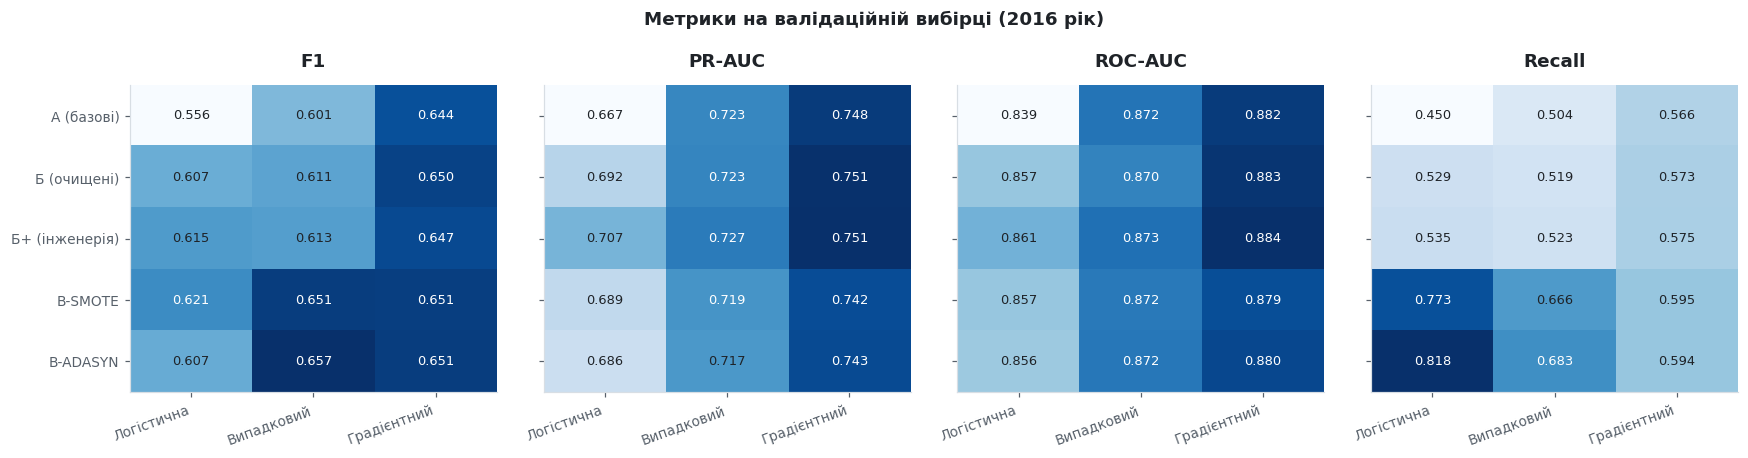

In [19]:
# --- Теплові карти основних метрик ---
show_metrics = ["F1", "PR-AUC", "ROC-AUC", "Recall"]
fig, axes = plt.subplots(1, len(show_metrics), figsize=(16, 4.2))

for ax, metric in zip(axes, show_metrics):
    pv = results.pivot(index="Сценарій", columns="Модель", values=metric)
    pv = pv.reindex(list(SCENARIOS.keys()))[MODEL_NAMES]

    # aspect="auto" розтягує клітинки під розмір панелі,
    # інакше вони були б квадратними й панель вийшла б вузькою.
    im = ax.imshow(pv.values, cmap=CMAP_SEQ, aspect="auto")
    ax.set_xticks(range(len(MODEL_NAMES)))
    # Довгі назви моделей скорочуємо до першого слова, інакше підписи зіллються
    ax.set_xticklabels([n.split()[0] for n in pv.columns], fontsize=9, rotation=20,
                       ha="right")
    ax.set_yticks(range(len(pv)))
    ax.set_yticklabels(pv.index if ax is axes[0] else [], fontsize=9)

    # Підписуємо кожну клітинку: з кольору точне значення не зчитати
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            # Колір тексту обираємо за яскравістю клітинки, щоб був контраст
            rel = (v - np.nanmin(pv.values)) / (np.ptp(pv.values) + 1e-9)
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8.5,
                    color="white" if rel > .6 else INK)
    ax.grid(False)
    style_axes(ax, title=metric)

fig.suptitle("Метрики на валідаційній вибірці (2016 рік)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 3.5 – вплив сценарію обробки на кожну модель

Групована стовпчикова діаграма: для кожної моделі показано, як змінюється метрика
при переході від сценарію до сценарію. Пунктир позначає рівень базового сценарію А,
тому приріст або втрату видно без обчислень.

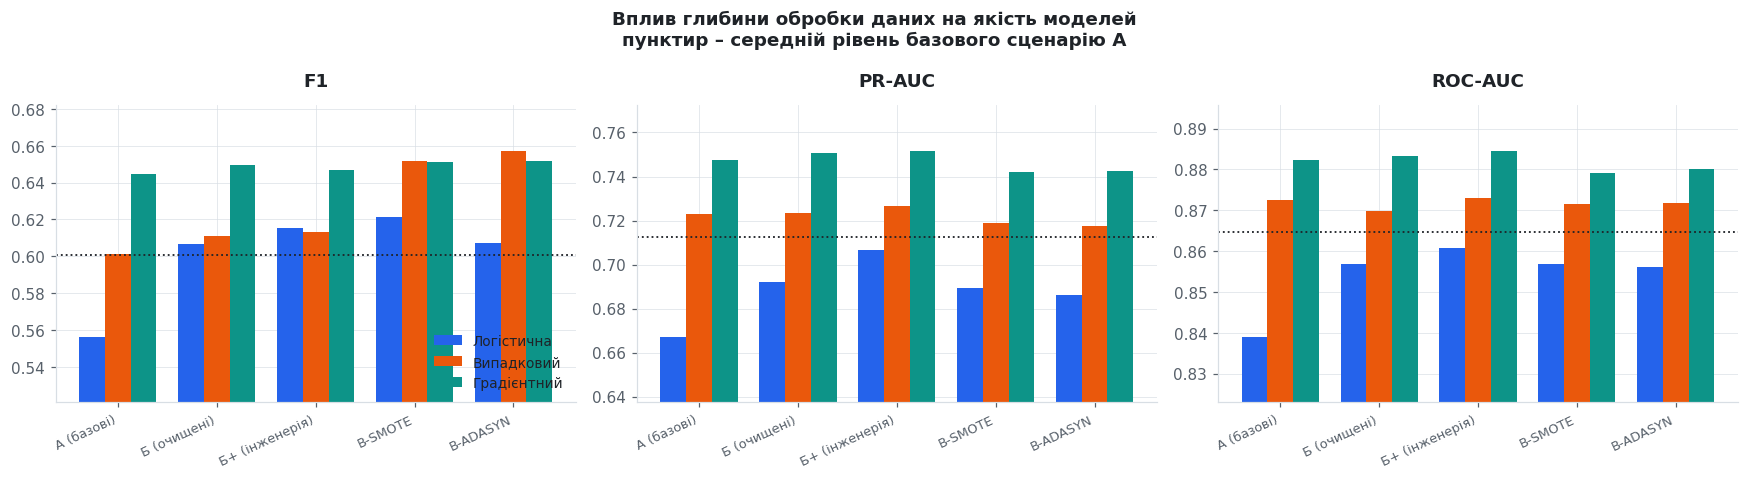

In [20]:
# --- Вплив сценарію обробки на метрики кожної моделі ---
plot_metrics = ["F1", "PR-AUC", "ROC-AUC"]
scen_list = list(SCENARIOS.keys())
x = np.arange(len(scen_list))
width = 0.26

fig, axes = plt.subplots(1, len(plot_metrics), figsize=(16, 4.4), sharex=True)

for ax, metric in zip(axes, plot_metrics):
    pv = results.pivot(index="Сценарій", columns="Модель",
                       values=metric).reindex(scen_list)[MODEL_NAMES]
    # Зсув (k - 1) * width розставляє три стовпці симетрично навколо позиції x
    for k, mdl in enumerate(MODEL_NAMES):
        ax.bar(x + (k - 1) * width, pv[mdl].values, width,
               color=PALETTE[k], label=mdl.split()[0] if ax is axes[0] else None)
    # Рівень базового сценарію А як точка відліку
    ax.axhline(pv.loc[scen_list[0]].mean(), color=INK, linestyle=":", linewidth=1.2)

    ax.set_xticks(x)
    ax.set_xticklabels(scen_list, rotation=25, ha="right", fontsize=8.5)
    # Звужуємо діапазон осі: усі значення лежать у вузькій смузі,
    # і від нуля різниця між стовпцями була б непомітна.
    lo, hi = np.nanmin(pv.values), np.nanmax(pv.values)
    ax.set_ylim(max(0, lo - (hi - lo) * .35), hi + (hi - lo) * .25)
    style_axes(ax, title=metric, ylabel="")

axes[0].legend(fontsize=9, loc="lower right")
fig.suptitle("Вплив глибини обробки даних на якість моделей\n"
             "пунктир – середній рівень базового сценарію А",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 3.6 – ROC- та PR-криві для сценарію Б

Метрики при фіксованому порозі 0,5 показують лише одну точку кривої. Повну картину
дають криві, побудовані за всіма можливими порогами.

**ROC-крива** відкладає частку істинно позитивних проти частки хибно позитивних.
**PR-крива** відкладає точність проти повноти і за сильного дисбалансу є
інформативнішою: вона взагалі не враховує істинно негативні випадки, яких у цій
задачі переважна більшість, тому не «розмивається» їхньою кількістю.

Горизонтальний пунктир на PR-кривій – рівень випадкового класифікатора, що дорівнює
частці позитивного класу.

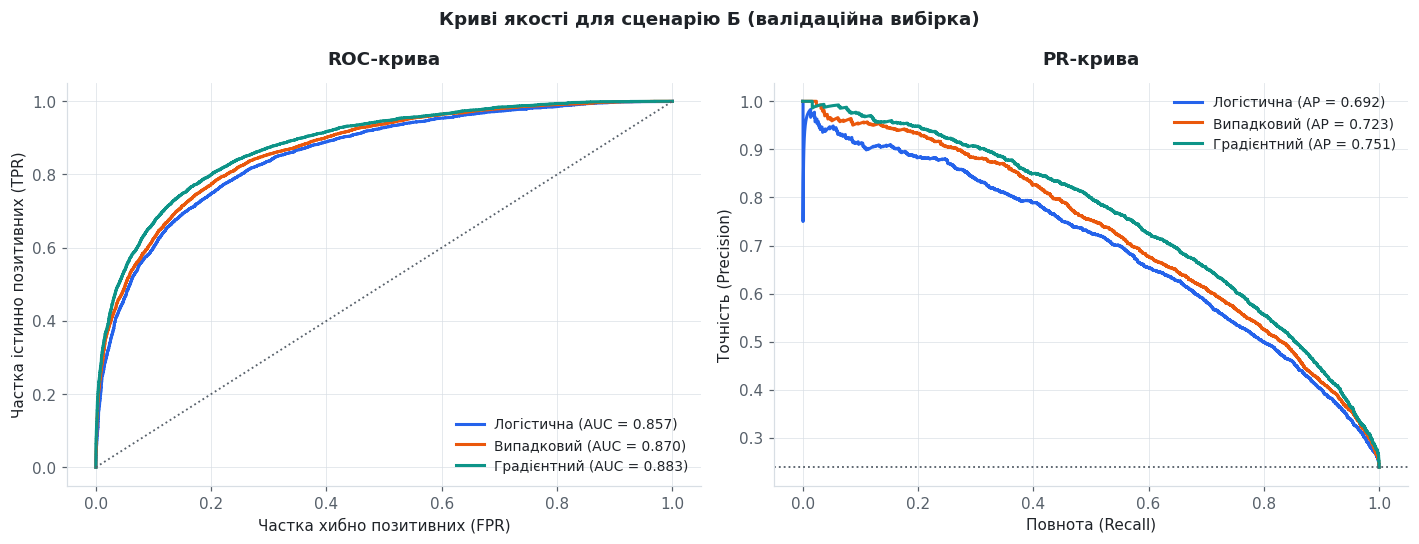

In [21]:
# --- ROC- та PR-криві (сценарій Б) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for k, mdl in enumerate(MODEL_NAMES):
    pr = proba_store[("Б (очищені)", mdl)]

    # ROC: частка хибно позитивних проти частки істинно позитивних.
    # Третє значення (пороги) не потрібне, тому відкидаємо його в _.
    fpr, tpr, _ = roc_curve(y_valid, pr)
    axes[0].plot(fpr, tpr, color=PALETTE[k],
                 label=f"{mdl.split()[0]} (AUC = {roc_auc_score(y_valid, pr):.3f})")

    # PR: повнота проти точності
    prec, rec, _ = precision_recall_curve(y_valid, pr)
    axes[1].plot(rec, prec, color=PALETTE[k],
                 label=f"{mdl.split()[0]} (AP = {average_precision_score(y_valid, pr):.3f})")

# Діагональ – випадковий класифікатор для ROC
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1.2)
# Для PR рівень випадкового класифікатора дорівнює частці позитивного класу
axes[1].axhline(y_valid.mean(), color=MUTED, linestyle=":", linewidth=1.2)

style_axes(axes[0], title="ROC-крива",
           xlabel="Частка хибно позитивних (FPR)",
           ylabel="Частка істинно позитивних (TPR)")
style_axes(axes[1], title="PR-крива",
           xlabel="Повнота (Recall)", ylabel="Точність (Precision)")
for ax in axes:
    ax.legend(fontsize=9)

fig.suptitle("Криві якості для сценарію Б (валідаційна вибірка)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 3.7 – матриці плутанини

Матриця плутанини показує структуру помилок, яку агреговані метрики приховують.
Для незбалансованої задачі принципово розрізняти два типи помилок: пропущений дощ
(хибно негативний) і хибна тривога (хибно позитивний).

Частки нормуємо **за рядками**, тобто за істинними класами: інакше рядок
мажоритарного класу переважив би картину просто через свій обсяг.

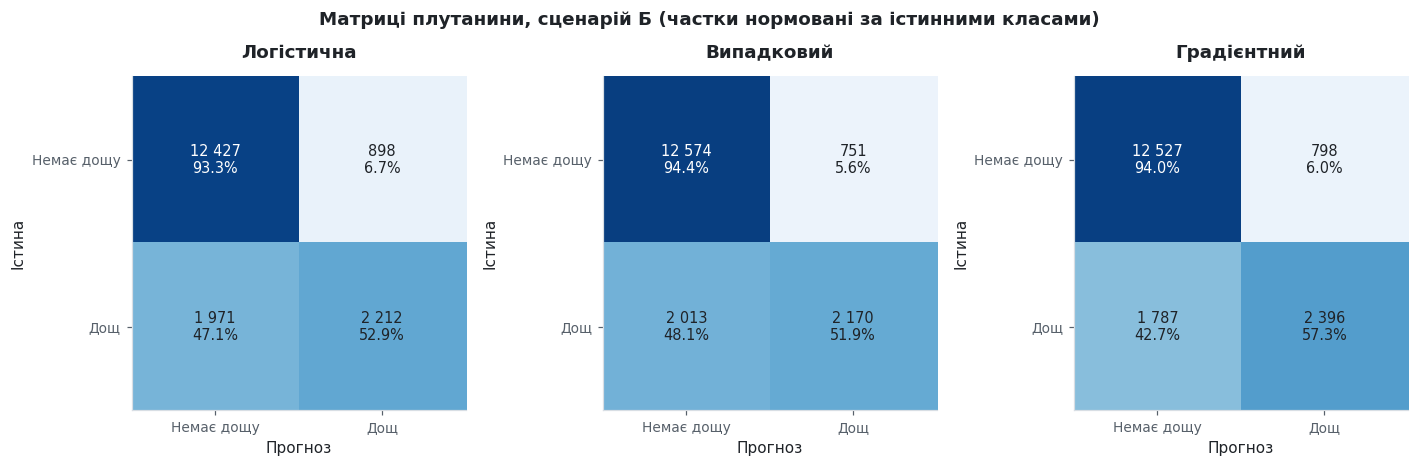

In [22]:
# --- Матриці плутанини для сценарію Б ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
labels = ["Немає дощу", "Дощ"]

for ax, mdl in zip(axes, MODEL_NAMES):
    pred = (proba_store[("Б (очищені)", mdl)] >= 0.5).astype(int)
    # confusion_matrix повертає матрицю 2x2: рядки – істина, стовпці – прогноз
    cm = confusion_matrix(y_valid, pred)
    # normalize="true" у вигляді явного ділення на суму рядка:
    # кожен рядок – істинний клас, тож частки читаються як Recall по класах.
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    ax.imshow(cm_norm, cmap=CMAP_SEQ, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", " ") + f"\n{cm_norm[i, j]:.1%}",
                    ha="center", va="center", fontsize=9.5,
                    color="white" if cm_norm[i, j] > .6 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(labels, fontsize=9)
    ax.set_yticks([0, 1]); ax.set_yticklabels(labels, fontsize=9)
    ax.grid(False)
    style_axes(ax, title=mdl.split()[0], xlabel="Прогноз", ylabel="Істина")

fig.suptitle("Матриці плутанини, сценарій Б (частки нормовані за істинними класами)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 3.8 – аналіз порога прийняття рішення

Поріг 0,5 є узгодженням, а не оптимумом: він був би природним за рівних класів і
рівної ціни двох типів помилок. За дисбалансу 1 : 3,5 обидві умови порушено.

Будуємо залежність Precision, Recall і F1 від порога та знаходимо поріг, що
максимізує F1. Це **альтернатива аугментації**: обидва підходи зміщують баланс
між точністю й повнотою, але підбір порога не потребує ані нових рядків, ані
повторного навчання.

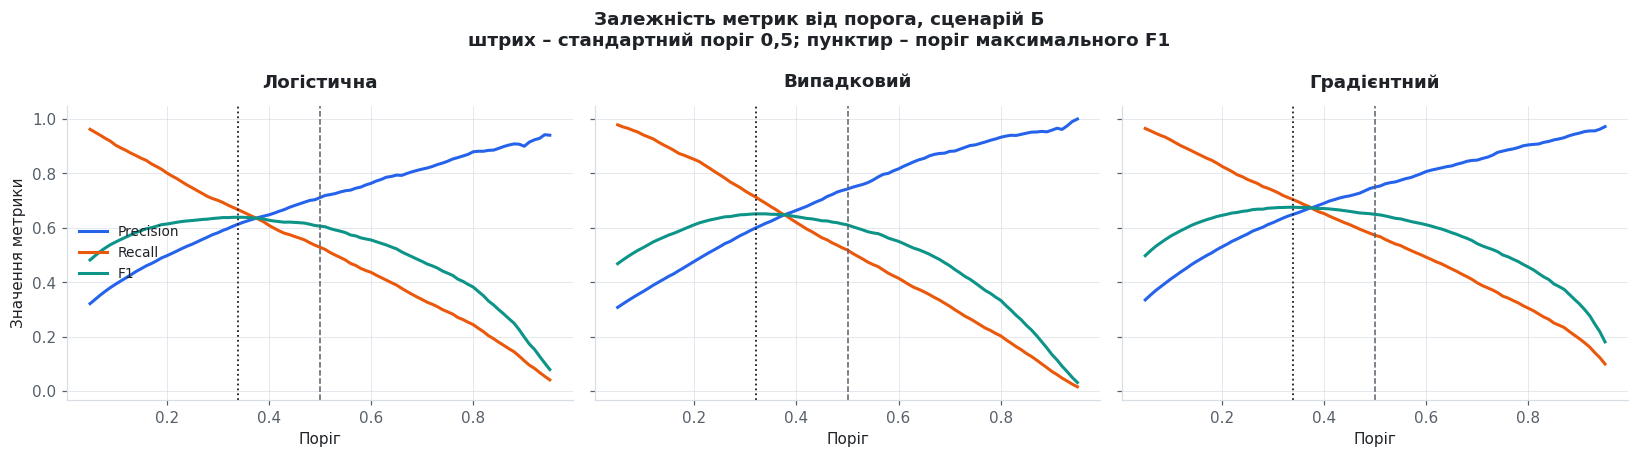

,Модель,"F1 при порозі 0,5",Оптимальний поріг,F1 при оптимальному порозі,Приріст F1
0,Логістична регресія,0.6066,0.34,0.6391,0.0325
1,Випадковий ліс,0.6109,0.32,0.6518,0.0409
2,Градієнтний бустинг,0.6496,0.34,0.6758,0.0262


In [23]:
# --- Залежність метрик від порога прийняття рішення ---
# Крайні пороги (0 і 1) не беремо: там одна з метрик вироджується
thresholds = np.linspace(0.05, 0.95, 91)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)

best_thr = {}
for ax, mdl in zip(axes, MODEL_NAMES):
    pr = proba_store[("Б (очищені)", mdl)]
    curves = {"Precision": [], "Recall": [], "F1": []}
    # Імовірності вже обчислено – змінюємо лише поріг, не перенавчаючи модель
    for t in thresholds:
        p = (pr >= t).astype(int)
        curves["Precision"].append(precision_score(y_valid, p, zero_division=0))
        curves["Recall"].append(recall_score(y_valid, p))
        curves["F1"].append(f1_score(y_valid, p))

    for k, (name, vals) in enumerate(curves.items()):
        ax.plot(thresholds, vals, color=PALETTE[k], label=name)

    # Поріг, що максимізує F1
    t_best = thresholds[int(np.argmax(curves["F1"]))]
    best_thr[mdl] = (t_best, max(curves["F1"]))
    # Дві вертикальні лінії: стандартний поріг і знайдений оптимум
    ax.axvline(t_best, color=INK, linestyle=":", linewidth=1.2)
    ax.axvline(0.5, color=MUTED, linestyle="--", linewidth=1)

    style_axes(ax, title=mdl.split()[0], xlabel="Поріг",
               ylabel="Значення метрики" if ax is axes[0] else "")

axes[0].legend(fontsize=9, loc="center left")
fig.suptitle("Залежність метрик від порога, сценарій Б\n"
             "штрих – стандартний поріг 0,5; пунктир – поріг максимального F1",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

thr_table = pd.DataFrame([
    {"Модель": m,
     "F1 при порозі 0,5": results[(results["Сценарій"] == "Б (очищені)") &
                                  (results["Модель"] == m)]["F1"].iloc[0],
     "Оптимальний поріг": round(t, 3),
     "F1 при оптимальному порозі": round(f, 4),
     "Приріст F1": round(f - results[(results["Сценарій"] == "Б (очищені)") &
                                     (results["Модель"] == m)]["F1"].iloc[0], 4)}
    for m, (t, f) in best_thr.items()
])
display(thr_table)


---
# Розділ 4. Сильні та слабкі сторони алгоритмів

**Завдання методички (пункт 5):** проаналізувати сильні та слабкі сторони кожного
алгоритму.

Замість переліку загальновідомих властивостей перевіряємо кожну з них **експериментом
на цих самих даних**: чутливість до масштабу ознак, поведінку при зростанні обсягу
вибірки, доступність інтерпретації та схильність до перенавчання.

### Комірка 4.1 – чутливість до масштабування ознак

Дерева розбивають простір порогами вигляду «ознака < значення», тому монотонне
перетворення шкали не змінює жодного розбиття – вони до масштабу **байдужі**.

Логістична регресія навчається градієнтним методом: якщо ознаки мають різні порядки
величин (тиск близько 1000 гПа проти хмарності від 0 до 8), поверхня функції втрат
стає витягнутою, і солвер збігається повільно або не встигає збігтися за відведену
кількість ітерацій.

Перевіряємо це прямо: навчаємо логістичну регресію на сценарії А **без** масштабування
і **з** `StandardScaler`, за інших рівних умов.

,Модель,F1 без масштабування,F1 з масштабуванням,Зміна F1,"Час без, с","Час з, с"
0,Логістична регресія,0.5561,0.5717,0.0156,20.5,0.5
1,Випадковий ліс,0.6014,0.6021,0.0007,56.9,58.2
2,Градієнтний бустинг,0.6444,0.6444,0.0000,4.5,4.8


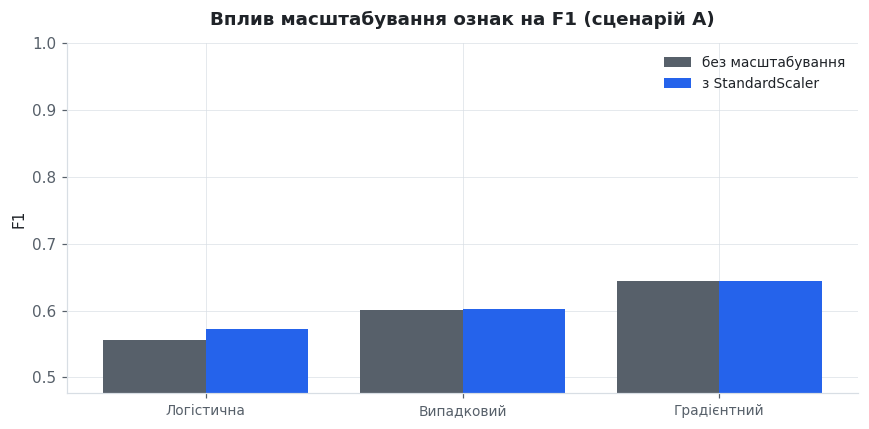

In [24]:
# --- Чутливість алгоритмів до масштабування ознак ---
scale_rows = []

# Масштабування навчаємо ЛИШЕ на train, інакше статистики валідації
# потрапили б у підготовку даних.
scaler = StandardScaler().fit(A_train)
A_train_sc = pd.DataFrame(scaler.transform(A_train), columns=A_train.columns)
A_valid_sc = pd.DataFrame(scaler.transform(A_valid), columns=A_valid.columns)

for mdl_name, mdl in make_models().items():
    # Без масштабування – беремо вже обчислений результат сценарію А,
    # щоб не навчати ту саму модель удруге.
    raw = results[(results["Сценарій"] == "А (базові)") &
                  (results["Модель"] == mdl_name)].iloc[0]
    # Зі масштабуванням – навчаємо заново на тих самих даних
    res_sc, _ = evaluate_model(mdl, A_train_sc, y_train, A_valid_sc, y_valid,
                               mdl_name, "А + StandardScaler")
    scale_rows.append({
        "Модель": mdl_name,
        "F1 без масштабування": raw["F1"],
        "F1 з масштабуванням": res_sc["F1"],
        "Зміна F1": round(res_sc["F1"] - raw["F1"], 4),
        "Час без, с": raw["Час, с"],
        "Час з, с": res_sc["Час, с"],
    })

scale_table = pd.DataFrame(scale_rows)
display(scale_table)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(scale_table))
ax.bar(x - 0.2, scale_table["F1 без масштабування"], 0.4,
       color=MUTED, label="без масштабування")
ax.bar(x + 0.2, scale_table["F1 з масштабуванням"], 0.4,
       color=PALETTE[0], label="з StandardScaler")
ax.set_xticks(x)
ax.set_xticklabels([n.split()[0] for n in scale_table["Модель"]], fontsize=9)
lo = min(scale_table["F1 без масштабування"].min(),
         scale_table["F1 з масштабуванням"].min())
ax.set_ylim(max(0, lo - 0.08), 1.0)
ax.legend(fontsize=9)
style_axes(ax, title="Вплив масштабування ознак на F1 (сценарій А)", ylabel="F1")
plt.tight_layout()
plt.show()


### Комірка 4.2 – масштабованість і час навчання

Час навчання – практичний критерій вибору алгоритму, особливо коли модель
доведеться перенавчати регулярно.

Вимірюємо, як зростає час навчання зі збільшенням обсягу вибірки. Додатково
включаємо **метод опорних векторів (SVM)** з ядром RBF: його складність становить
від O(n²) до O(n³) за кількістю спостережень, тому на повній вибірці зі 116 тисяч
рядків він непридатний. Саме тому SVM не увійшов до основного порівняння –
і цей висновок теж варто підтвердити вимірюванням, а не прийняти на віру.

Логарифмічна шкала за віссю часу обов'язкова: значення різняться на кілька порядків.

  n =  2 000 – готово
  n =  5 000 – готово
  n = 10 000 – готово
  n = 25 000 – готово
  n = 50 000 – готово
  n = 116 219 – готово
  SVM n =  1 000 – готово
  SVM n =  2 000 – готово
  SVM n =  4 000 – готово
  SVM n =  8 000 – готово
  SVM n = 16 000 – готово


Модель,SVM (RBF),Випадковий ліс,Градієнтний бустинг,Логістична регресія
Рядків,,,,
1000,0.04,NaN,NaN,NaN
2000,0.15,1.23,1.42,0.02
4000,0.52,NaN,NaN,NaN
5000,NaN,3.43,4.62,0.05
8000,2.03,NaN,NaN,NaN
10000,NaN,9.15,3.49,0.37
16000,8.33,NaN,NaN,NaN
25000,NaN,11.75,4.12,0.28
50000,NaN,24.15,6.91,0.48


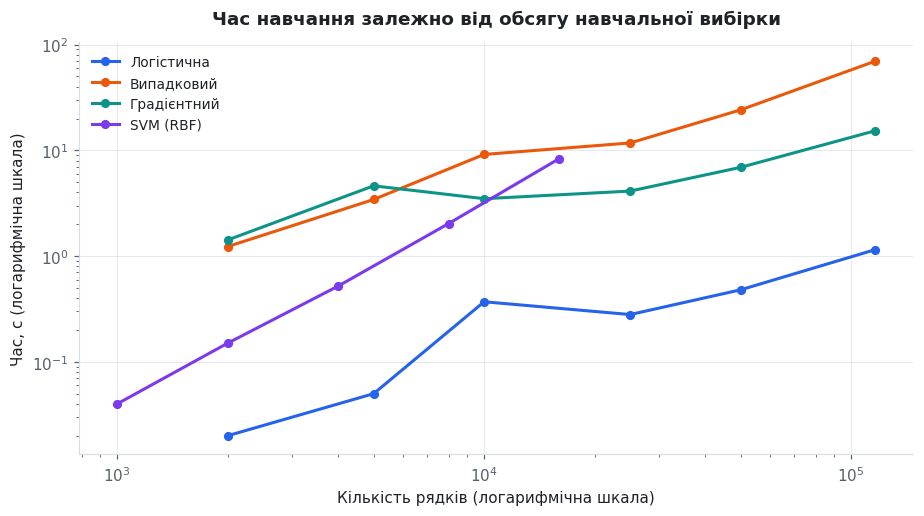

In [25]:
# --- Масштабованість: час навчання залежно від обсягу вибірки ---
sizes = [2000, 5000, 10000, 25000, 50000, len(B_train)]
svm_sizes = [1000, 2000, 4000, 8000, 16000]   # для SVM – значно менші обсяги

timing_rows = []
# default_rng – сучасний генератор NumPy; із фіксованим зерном
# підвибірки будуть тими самими при кожному запуску.
rng_s = np.random.default_rng(RANDOM_STATE)

for n in sizes:
    # Випадкова підвибірка фіксованого розміру з навчальних даних
    idx = rng_s.choice(len(B_train), n, replace=False)
    Xn, yn = B_train.iloc[idx], y_train[idx]
    for mdl_name, mdl in make_models().items():
        # Нас цікавить лише час навчання, тому прогнози тут не обчислюємо
        t0 = time.time()
        mdl.fit(Xn, yn)
        timing_rows.append({"Модель": mdl_name, "Рядків": n,
                            "Час, с": round(time.time() - t0, 2)})
    print(f"  n = {n:>6,}".replace(",", " ") + " – готово")

# SVM з ядром RBF: вимірюємо окремо й на менших обсягах
for n in svm_sizes:
    idx = rng_s.choice(len(B_train), n, replace=False)
    t0 = time.time()
    SVC(kernel="rbf", random_state=RANDOM_STATE).fit(B_train.iloc[idx], y_train[idx])
    timing_rows.append({"Модель": "SVM (RBF)", "Рядків": n,
                        "Час, с": round(time.time() - t0, 2)})
    print(f"  SVM n = {n:>6,}".replace(",", " ") + " – готово")

timing = pd.DataFrame(timing_rows)
display(timing.pivot(index="Рядків", columns="Модель", values="Час, с"))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for k, mdl in enumerate(MODEL_NAMES + ["SVM (RBF)"]):
    sub = timing[timing["Модель"] == mdl]
    ax.plot(sub["Рядків"], sub["Час, с"], marker="o", markersize=5,
            color=PALETTE[k], label=mdl.split()[0] if mdl != "SVM (RBF)" else "SVM (RBF)")
# Обидві осі логарифмічні: і обсяги, і час різняться на порядки,
# а на лог-лог шкалі степенева залежність виглядає прямою.
ax.set_xscale("log"); ax.set_yscale("log")
ax.legend(fontsize=9)
style_axes(ax, title="Час навчання залежно від обсягу навчальної вибірки",
           xlabel="Кількість рядків (логарифмічна шкала)",
           ylabel="Час, с (логарифмічна шкала)")
plt.tight_layout()
plt.show()


### Комірка 4.3 – інтерпретованість моделей

Три алгоритми дають принципово різний доступ до пояснення власних рішень.

**Логістична регресія** повертає коефіцієнти: їхній знак показує напрямок впливу
ознаки, а величина – силу. Це єдина з трьох моделей, що дає напрямок.

**Випадковий ліс** повертає важливості за зменшенням домішки (impurity). Вони
показують лише силу впливу, без знака, і мають відому ваду: систематично завищують
важливість ознак із великою кількістю унікальних значень.

**Градієнтний бустинг** у реалізації `HistGradientBoosting` вбудованих важливостей не
має взагалі, тому використовуємо **перестановочну важливість**: ознаку випадково
перемішують і дивляться, наскільки впаде метрика. Цей метод модельно-незалежний,
але обчислювально дорожчий, тому застосовуємо його до підвибірки валідації.

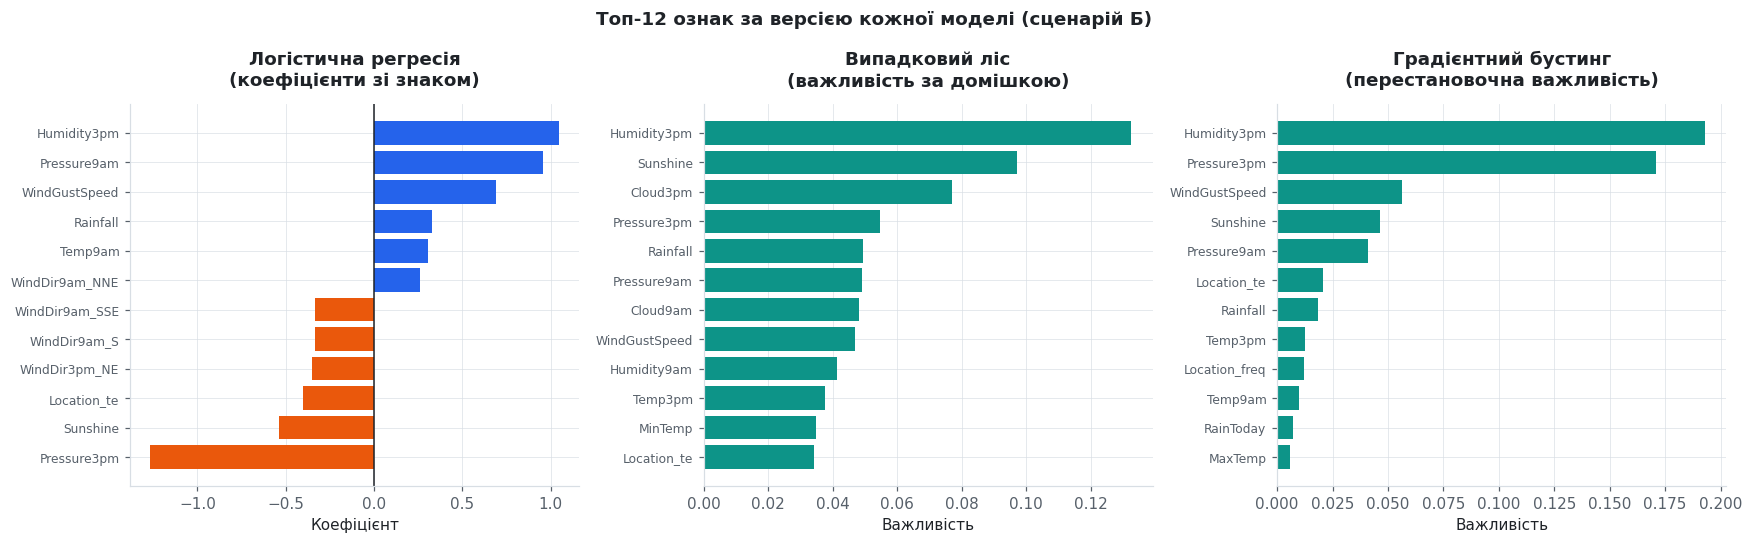

Спільних ознак у топ-5 випадкового лісу та градієнтного бустингу: 3
  Humidity3pm, Pressure3pm, Sunshine


In [26]:
# --- Інтерпретованість: що кожна модель може сказати про ознаки ---
TOP_N = 12

# 1. Логістична регресія: коефіцієнти зі знаком.
# coef_ має форму (1, n_features) для бінарної задачі, тому беремо [0].
coefs = pd.Series(fitted_b["Логістична регресія"].coef_[0],
                  index=B_train.columns).sort_values()
# Беремо найбільші за модулем – половину з кожного кінця
top_coefs = pd.concat([coefs.head(TOP_N // 2), coefs.tail(TOP_N // 2)])

# 2. Випадковий ліс: важливості за зменшенням домішки
rf_imp = pd.Series(fitted_b["Випадковий ліс"].feature_importances_,
                   index=B_train.columns).sort_values(ascending=False).head(TOP_N)

# 3. Градієнтний бустинг: перестановочна важливість на підвибірці валідації.
# n_repeats=3 – кожну ознаку перемішуємо тричі й усереднюємо падіння метрики;
# підвибірка з 5000 рядків потрібна, бо метод вимагає n_features * n_repeats
# повних проходів прогнозування.
sub = np.random.default_rng(RANDOM_STATE).choice(len(B_valid), 5000, replace=False)
perm = permutation_importance(fitted_b["Градієнтний бустинг"],
                              B_valid.iloc[sub], y_valid[sub],
                              n_repeats=3, random_state=RANDOM_STATE,
                              scoring="average_precision")
gb_imp = pd.Series(perm.importances_mean,
                   index=B_train.columns).sort_values(ascending=False).head(TOP_N)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Коефіцієнти мають знак -> дивергентне кодування кольором двома полюсами
axes[0].barh(range(len(top_coefs)), top_coefs.values,
             color=[PALETTE[1] if v < 0 else PALETTE[0] for v in top_coefs.values])
axes[0].set_yticks(range(len(top_coefs)))
axes[0].set_yticklabels(top_coefs.index, fontsize=8)
axes[0].axvline(0, color=INK, linewidth=1)
style_axes(axes[0], title="Логістична регресія\n(коефіцієнти зі знаком)",
           xlabel="Коефіцієнт")

for ax, (imp, title) in zip(axes[1:], [
        (rf_imp, "Випадковий ліс\n(важливість за домішкою)"),
        (gb_imp, "Градієнтний бустинг\n(перестановочна важливість)")]):
    vals = imp.iloc[::-1]
    ax.barh(range(len(vals)), vals.values, color=PALETTE[2])
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(vals.index, fontsize=8)
    style_axes(ax, title=title, xlabel="Важливість")

fig.suptitle(f"Топ-{TOP_N} ознак за версією кожної моделі (сценарій Б)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Скільки ознак спільні в трійці найважливіших за різними методами
common = set(rf_imp.head(5).index) & set(gb_imp.head(5).index)
print(f"Спільних ознак у топ-5 випадкового лісу та градієнтного бустингу: {len(common)}")
print(f"  {', '.join(sorted(common)) if common else '–'}")


### Комірка 4.4 – гнучкість моделі та перенавчання: глибина дерева

Найнаочніша демонстрація перенавчання – одне дерево рішень зі зростальною
максимальною глибиною. Глибина прямо керує ємністю моделі: кожен додатковий рівень
подвоює кількість листків, тобто кількість областей, на які ділиться простір ознак.

Спостерігаємо класичну картину: якість на навчальній вибірці зростає монотонно аж до
повного запам'ятовування, тоді як якість на валідації спершу зростає, досягає
максимуму, а далі падає. Відстань між двома кривими і є **розривом узагальнення**.

Ця комірка пояснює, чому випадковий ліс із сотень глибоких дерев усе ж не
перенавчається так само: усереднення незалежних дерев зменшує дисперсію прогнозу.

,Глибина,Листків,F1 навчання,F1 валідація,Розрив
0,1,2,0.5348,0.5329,0.0019
1,2,4,0.4037,0.4052,-0.0015
2,3,8,0.4922,0.4773,0.0149
3,4,16,0.5328,0.5207,0.0121
4,6,64,0.5867,0.5704,0.0163
5,8,238,0.6043,0.5745,0.0298
6,10,769,0.6488,0.5798,0.0690
7,12,1943,0.7070,0.5741,0.1329
8,15,4761,0.8150,0.5576,0.2575
9,20,9502,0.9436,0.5413,0.4023


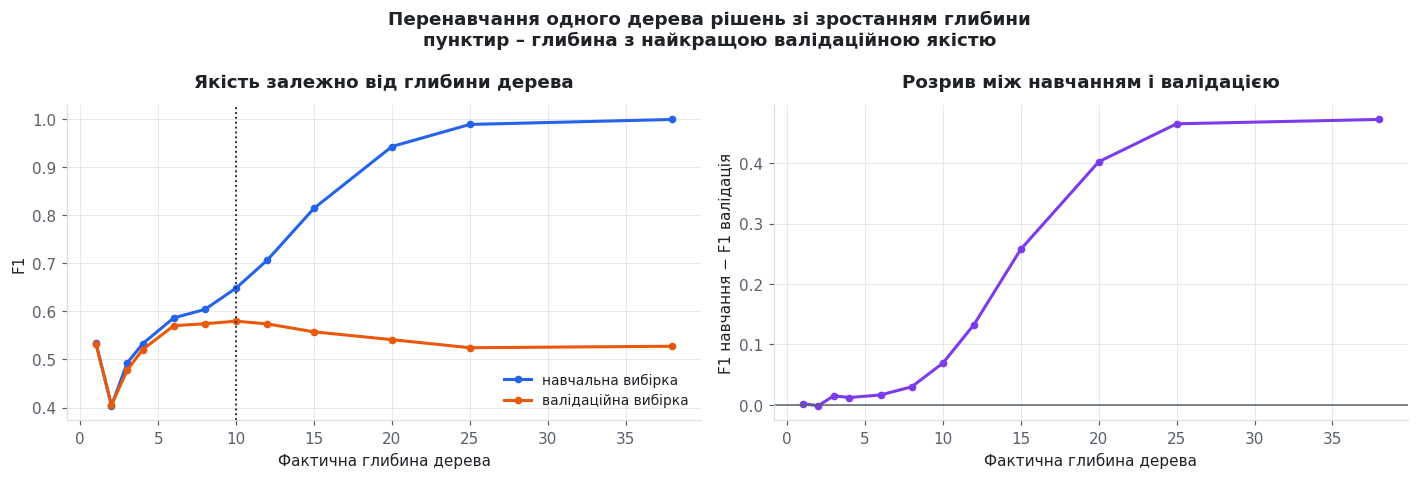

In [27]:
# --- Глибина дерева рішень: ємність моделі проти узагальнення ---
depths = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 25, None]
depth_rows = []

# Глибини подано нерівномірно: на малих значеннях картина змінюється швидко,
# на великих – повільно, тому густіша сітка потрібна саме на початку.
for d in depths:
    # max_depth=None означає "без обмеження": дерево росте,
    # доки кожен листок не стане однорідним.
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    tree.fit(B_train, y_train)
    f1_tr = f1_score(y_train, tree.predict(B_train))
    f1_va = f1_score(y_valid, tree.predict(B_valid))
    # get_depth() повертає ФАКТИЧНУ глибину: за max_depth=None дерево
    # зупиняється само, і задане обмеження нічого не каже про результат.
    depth_rows.append({
        "Глибина": "без обмеження" if d is None else d,
        "_d": tree.get_depth(),           # фактична глибина навченого дерева
        "Листків": tree.get_n_leaves(),
        "F1 навчання": round(f1_tr, 4),
        "F1 валідація": round(f1_va, 4),
        "Розрив": round(f1_tr - f1_va, 4),
    })

depth_df = pd.DataFrame(depth_rows)
display(depth_df.drop(columns="_d"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

axes[0].plot(depth_df["_d"], depth_df["F1 навчання"], marker="o", markersize=4,
             color=PALETTE[0], label="навчальна вибірка")
axes[0].plot(depth_df["_d"], depth_df["F1 валідація"], marker="o", markersize=4,
             color=PALETTE[1], label="валідаційна вибірка")
# Позначаємо глибину з найкращою валідаційною якістю
best_i = int(depth_df["F1 валідація"].idxmax())
axes[0].axvline(depth_df["_d"].iloc[best_i], color=INK, linestyle=":", linewidth=1.2)
axes[0].legend(fontsize=9)
style_axes(axes[0], title="Якість залежно від глибини дерева",
           xlabel="Фактична глибина дерева", ylabel="F1")

axes[1].plot(depth_df["_d"], depth_df["Розрив"], marker="o", markersize=4,
             color=PALETTE[3])
axes[1].axhline(0, color=MUTED, linewidth=1)
style_axes(axes[1], title="Розрив між навчанням і валідацією",
           xlabel="Фактична глибина дерева", ylabel="F1 навчання − F1 валідація")

fig.suptitle("Перенавчання одного дерева рішень зі зростанням глибини\n"
             "пунктир – глибина з найкращою валідаційною якістю",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 4.5 – зведення сильних і слабких сторін

Зводимо результати всіх попередніх комірок розділу в одну таблицю. Кожне твердження
спирається на конкретний вимір у цьому ноутбуці, а не на загальні міркування.

In [28]:
# --- Підсумкова таблиця сильних і слабких сторін ---
# Числові підтвердження беремо з уже обчислених таблиць, нічого не вписуючи вручну.
def _m(scen, mdl, col):
    """Дістає одне значення з таблиці результатів за трьома ключами."""
    return results[(results["Сценарій"] == scen) & (results["Модель"] == mdl)][col].iloc[0]

# Кожне твердження в таблиці підкріплене числом із попередніх комірок:
# часом навчання, розривом узагальнення та PR-AUC на сценарії Б.
strengths = pd.DataFrame([
    {
        "Модель": "Логістична регресія",
        "Сильні сторони": "найшвидше навчання; коефіцієнти зі знаком дають "
                          "напрямок впливу ознаки; стійка до перенавчання",
        "Слабкі сторони": "лінійна межа рішень не описує взаємодії ознак; "
                          "вимагає масштабування",
        "Час на повній вибірці, с": _m("Б (очищені)", "Логістична регресія", "Час, с"),
        "Розрив F1": _m("Б (очищені)", "Логістична регресія", "Розрив F1"),
        "PR-AUC (Б)": _m("Б (очищені)", "Логістична регресія", "PR-AUC"),
    },
    {
        "Модель": "Випадковий ліс",
        "Сильні сторони": "не потребує масштабування; стійкий до викидів; "
                          "дерева навчаються паралельно",
        "Слабкі сторони": "найдовше навчання та найбільший обсяг пам'яті; "
                          "важливості завищені для ознак із багатьма значеннями",
        "Час на повній вибірці, с": _m("Б (очищені)", "Випадковий ліс", "Час, с"),
        "Розрив F1": _m("Б (очищені)", "Випадковий ліс", "Розрив F1"),
        "PR-AUC (Б)": _m("Б (очищені)", "Випадковий ліс", "PR-AUC"),
    },
    {
        "Модель": "Градієнтний бустинг",
        "Сильні сторони": "найвища якість за більшістю метрик; працює з пропусками; "
                          "не потребує масштабування",
        "Слабкі сторони": "немає вбудованих важливостей – потрібен дорожчий "
                          "перестановочний аналіз; послідовне навчання не "
                          "розпаралелюється за деревами",
        "Час на повній вибірці, с": _m("Б (очищені)", "Градієнтний бустинг", "Час, с"),
        "Розрив F1": _m("Б (очищені)", "Градієнтний бустинг", "Розрив F1"),
        "PR-AUC (Б)": _m("Б (очищені)", "Градієнтний бустинг", "PR-AUC"),
    },
])

# За замовчуванням pandas обрізає довгий текст – тимчасово знімаємо обмеження
pd.set_option("display.max_colwidth", 95)
display(strengths)
pd.reset_option("display.max_colwidth")


,Модель,Сильні сторони,Слабкі сторони,"Час на повній вибірці, с",Розрив F1,PR-AUC (Б)
0,Логістична регресія,найшвидше навчання; коефіцієнти зі знаком дають напрямок впливу ознаки; стійка до перенавчання,лінійна межа рішень не описує взаємодії ознак; вимагає масштабування,1.1,-0.0013,0.6920
1,Випадковий ліс,не потребує масштабування; стійкий до викидів; дерева навчаються паралельно,найдовше навчання та найбільший обсяг пам'яті; важливості завищені для ознак із багатьма зн...,63.9,0.3376,0.7234
2,Градієнтний бустинг,найвища якість за більшістю метрик; працює з пропусками; не потребує масштабування,немає вбудованих важливостей – потрібен дорожчий перестановочний аналіз; послідовне навчанн...,14.8,0.0610,0.7508


---
# Розділ 5. Аугментація та перенавчання

**Завдання методички (пункт 6):** детальний аналіз того, чи покращила аугментація
якість передбачення і за яких умов вона може викликати перенавчання.

Розділ відповідає на два питання окремо. Спершу – **чи допомогла** аугментація, за
якими саме метриками і якою ціною. Потім – **за яких умов** вона шкодить: розглядаємо
чотири різні механізми, кожен із кількісною демонстрацією.

### Комірка 5.1 – чи покращила аугментація якість передбачення

Порівнюємо сценарії В-SMOTE і В-ADASYN зі сценарієм Б, на якому вони побудовані.
Точкою відліку є саме Б, а не А: аугментацію застосовано до очищених даних, тому
коректно вимірювати приріст відносно них.

Зміни подаємо зі знаком. Дивергентна шкала кольору тут доречна, бо величина має
природну середину – нуль, що означає відсутність зміни.

,Сценарій,Модель,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,В-SMOTE,Логістична регресія,-0.0613,-0.1920,0.2441,0.0146,0.0000,-0.0026
1,В-SMOTE,Випадковий ліс,-0.0123,-0.1050,0.1470,0.0406,0.0017,-0.0047
2,В-SMOTE,Градієнтний бустинг,-0.0047,-0.0310,0.0217,0.0014,-0.0043,-0.0088
3,В-ADASYN,Логістична регресія,-0.0887,-0.2282,0.2890,0.0008,-0.0008,-0.0059
4,В-ADASYN,Випадковий ліс,-0.0125,-0.1101,0.1640,0.0460,0.0020,-0.0061
5,В-ADASYN,Градієнтний бустинг,-0.0042,-0.0289,0.0213,0.0019,-0.0032,-0.0082


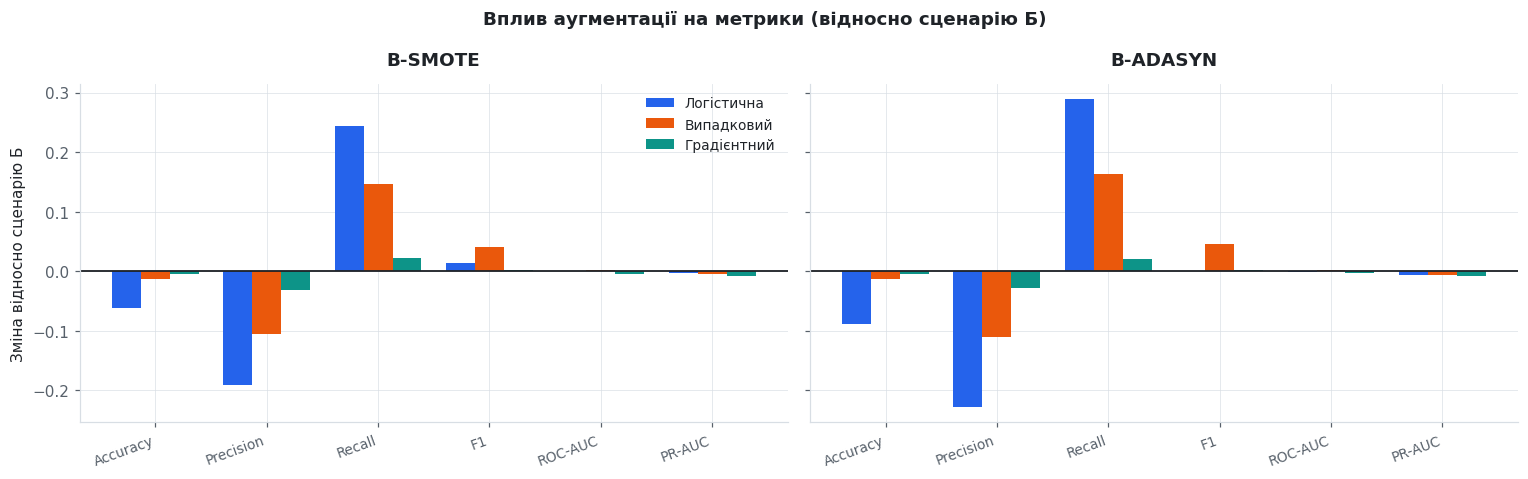

In [29]:
# --- Приріст метрик від аугментації відносно сценарію Б ---
base_b = results[results["Сценарій"] == "Б (очищені)"].set_index("Модель")
delta_rows = []

for scen in ["В-SMOTE", "В-ADASYN"]:
    # set_index("Модель") дозволяє віднімати рядки за назвою моделі,
    # не покладаючись на збіг порядку рядків у двох таблицях.
    sub = results[results["Сценарій"] == scen].set_index("Модель")
    for mdl in MODEL_NAMES:
        row = {"Сценарій": scen, "Модель": mdl}
        for metric in METRIC_COLS:
            row[metric] = round(sub.loc[mdl, metric] - base_b.loc[mdl, metric], 4)
        delta_rows.append(row)

delta = pd.DataFrame(delta_rows)
display(delta)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, scen in zip(axes, ["В-SMOTE", "В-ADASYN"]):
    sub = delta[delta["Сценарій"] == scen]
    x = np.arange(len(METRIC_COLS))
    for k, mdl in enumerate(MODEL_NAMES):
        vals = sub[sub["Модель"] == mdl][METRIC_COLS].values[0]
        ax.bar(x + (k - 1) * 0.26, vals, 0.26, color=PALETTE[k],
               label=mdl.split()[0] if ax is axes[0] else None)
    # Нуль – природна точка відліку: вище нього покращення, нижче – погіршення
    ax.axhline(0, color=INK, linewidth=1.2)
    ax.set_xticks(x); ax.set_xticklabels(METRIC_COLS, rotation=20, ha="right", fontsize=9)
    style_axes(ax, title=scen, ylabel="Зміна відносно сценарію Б" if ax is axes[0] else "")

axes[0].legend(fontsize=9)
fig.suptitle("Вплив аугментації на метрики (відносно сценарію Б)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 5.2 – розрив між навчанням і валідацією як міра перенавчання

Перенавчання вимірюємо прямо: різницею F1 на навчальній вибірці та на валідаційній.
Що більший розрив, то більше модель запам'ятала замість того, щоб узагальнити.

Для аугментованих сценаріїв розрив обчислюється відносно **аугментованої** навчальної
вибірки – саме на ній модель навчалася, і саме її вона могла запам'ятати.

Модель,Логістична регресія,Випадковий ліс,Градієнтний бустинг
Сценарій,,,
А (базові),0.0236,0.3661,0.0608
Б (очищені),-0.0013,0.3376,0.0610
Б+ (інженерія),-0.0011,0.3616,0.0793
В-SMOTE,0.1720,0.3435,0.2674
В-ADASYN,0.1459,0.3405,0.2648


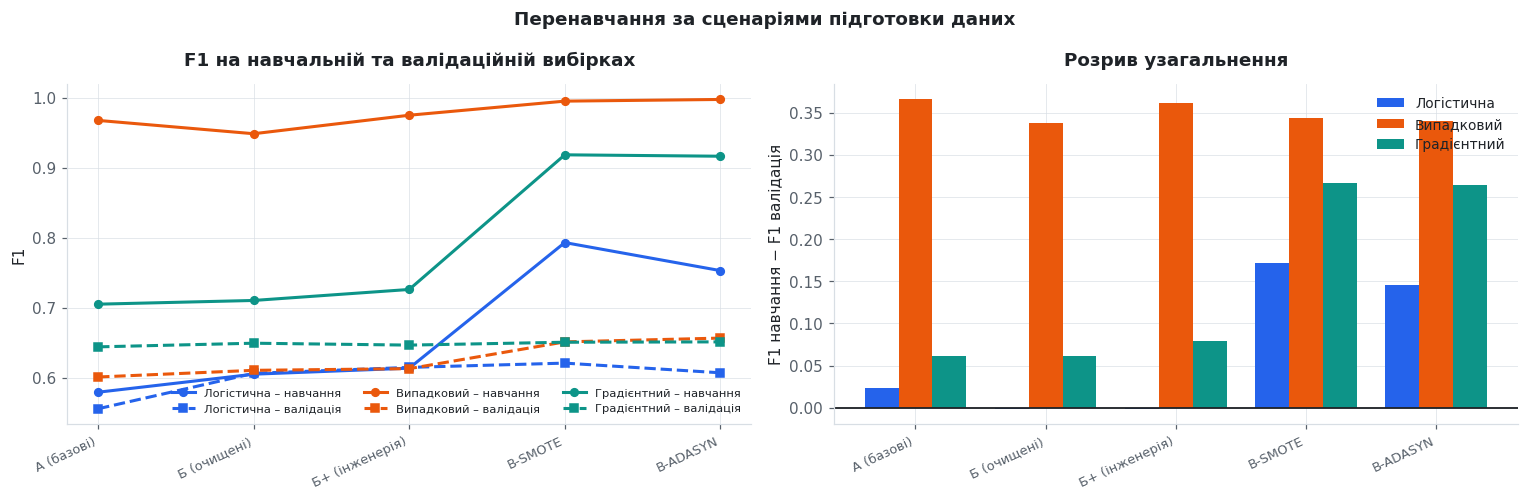

In [30]:
# --- Розрив між навчанням і валідацією за всіма сценаріями ---
# Розрив уже обчислено в комірці 3.1 – тут лише розгортаємо його у таблицю
gap_pivot = results.pivot(index="Сценарій", columns="Модель",
                          values="Розрив F1").reindex(list(SCENARIOS.keys()))[MODEL_NAMES]
display(gap_pivot)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# Ліва панель: абсолютні рівні F1 на навчанні та валідації.
# Суцільна лінія – навчання, штрихова – валідація; колір кодує модель.
x = np.arange(len(SCENARIOS))
for k, mdl in enumerate(MODEL_NAMES):
    sub = results[results["Модель"] == mdl].set_index("Сценарій").reindex(list(SCENARIOS.keys()))
    axes[0].plot(x, sub["F1 train"], marker="o", markersize=5, color=PALETTE[k],
                 label=f"{mdl.split()[0]} – навчання")
    axes[0].plot(x, sub["F1"], marker="s", markersize=5, color=PALETTE[k],
                 linestyle="--", label=f"{mdl.split()[0]} – валідація")
axes[0].set_xticks(x)
axes[0].set_xticklabels(list(SCENARIOS.keys()), rotation=25, ha="right", fontsize=8.5)
axes[0].legend(fontsize=7.5, ncol=3)
style_axes(axes[0], title="F1 на навчальній та валідаційній вибірках", ylabel="F1")

# Права панель: сам розрив як окрема величина
for k, mdl in enumerate(MODEL_NAMES):
    axes[1].bar(x + (k - 1) * 0.26, gap_pivot[mdl].values, 0.26,
                color=PALETTE[k], label=mdl.split()[0])
axes[1].axhline(0, color=INK, linewidth=1.2)
axes[1].set_xticks(x)
axes[1].set_xticklabels(list(SCENARIOS.keys()), rotation=25, ha="right", fontsize=8.5)
axes[1].legend(fontsize=9)
style_axes(axes[1], title="Розрив узагальнення",
           ylabel="F1 навчання − F1 валідація")

fig.suptitle("Перенавчання за сценаріями підготовки даних",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 5.3 – криві навчання

Крива навчання показує, як змінюються обидві метрики зі збільшенням обсягу навчальних
даних. Вона розрізняє дві різні причини низької якості:

* криві зійшлися на низькому рівні – модель **недонавчена** (зміщення), додавання
  даних не допоможе, потрібна гнучкіша модель;
* між кривими залишається широкий проміжок – модель **перенавчена** (дисперсія),
  і додавання даних має зменшити розрив.

Будуємо криві для градієнтного бустингу на сценаріях Б і В-SMOTE. Важливо, що
валідаційна вибірка в обох випадках реальна й незмінна – зростає лише обсяг навчання.

Б (очищені): криву побудовано
В-SMOTE: криву побудовано


,Сценарій,Частка,Рядків,F1 навчання,F1 валідація,Розрив
0,Б (очищені),0.05,5810,1.0000,0.6025,0.3975
1,Б (очищені),0.10,11621,0.9756,0.6117,0.3639
2,Б (очищені),0.20,23243,0.8720,0.6296,0.2424
3,Б (очищені),0.40,46487,0.7816,0.6415,0.1401
4,Б (очищені),0.70,81353,0.7277,0.6433,0.0844
5,Б (очищені),1.00,116219,0.7106,0.6496,0.0610
6,В-SMOTE,0.05,9028,0.9994,0.6327,0.3667
7,В-SMOTE,0.10,18057,0.9808,0.6402,0.3405
8,В-SMOTE,0.20,36115,0.9545,0.6379,0.3166
9,В-SMOTE,0.40,72230,0.9314,0.6474,0.2840


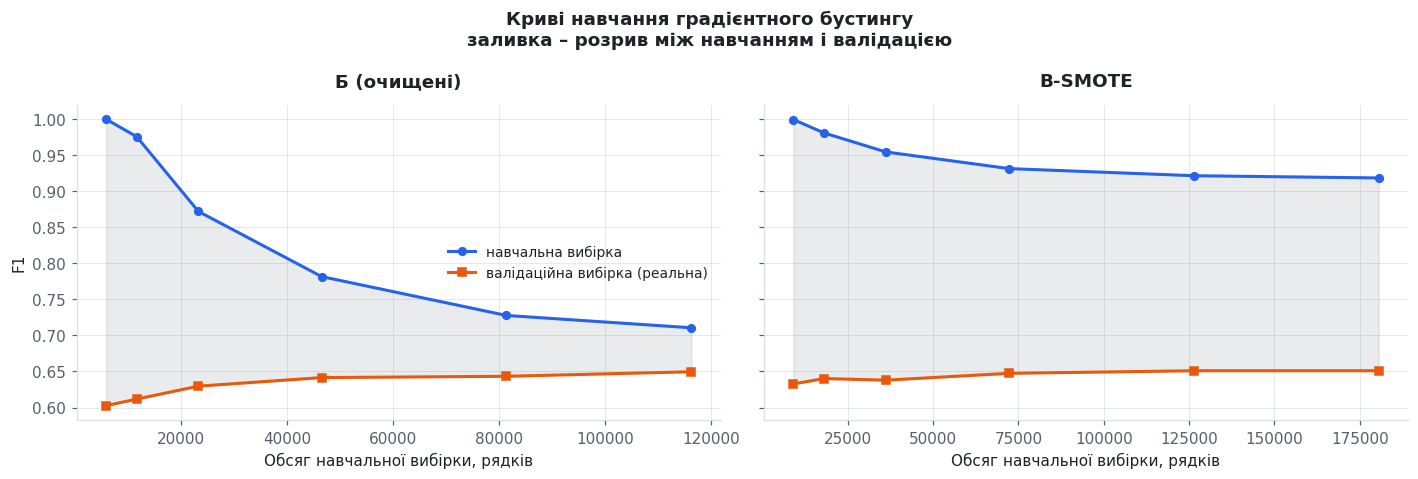

In [31]:
# --- Криві навчання: сценарій Б проти В-SMOTE ---
fractions = [0.05, 0.1, 0.2, 0.4, 0.7, 1.0]   # частки навчальної вибірки
curve_rows = []
rng_c = np.random.default_rng(RANDOM_STATE)

for scen_name, (Xs, ys) in [("Б (очищені)", (B_train, y_train)),
                            ("В-SMOTE", (V_sm_train, y_sm_train))]:
    for frac in fractions:
        n = int(len(Xs) * frac)
        idx = rng_c.choice(len(Xs), n, replace=False)
        # Підвибірка випадкова, а не перші n рядків: інакше у малих обсягах
        # опинилися б лише найраніші роки й найперші станції.
        Xn = Xs.iloc[idx] if hasattr(Xs, "iloc") else Xs[idx]
        yn = ys[idx]

        # Модель однакова на всіх точках кривої: змінюється лише обсяг даних
        mdl = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                             early_stopping=False,
                                             random_state=RANDOM_STATE)
        mdl.fit(Xn, yn)
        f1_tr = f1_score(yn, (mdl.predict_proba(Xn)[:, 1] >= .5).astype(int))
        # Валідація завжди та сама й завжди реальна – це точка відліку
        f1_va = f1_score(y_valid, (mdl.predict_proba(B_valid)[:, 1] >= .5).astype(int))
        curve_rows.append({"Сценарій": scen_name, "Частка": frac, "Рядків": n,
                           "F1 навчання": round(f1_tr, 4),
                           "F1 валідація": round(f1_va, 4),
                           "Розрив": round(f1_tr - f1_va, 4)})
    print(f"{scen_name}: криву побудовано")

curves = pd.DataFrame(curve_rows)
display(curves)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, scen in zip(axes, ["Б (очищені)", "В-SMOTE"]):
    sub = curves[curves["Сценарій"] == scen]
    ax.plot(sub["Рядків"], sub["F1 навчання"], marker="o", markersize=5,
            color=PALETTE[0], label="навчальна вибірка")
    ax.plot(sub["Рядків"], sub["F1 валідація"], marker="s", markersize=5,
            color=PALETTE[1], label="валідаційна вибірка (реальна)")
    # Заливка між кривими робить розрив узагальнення видимим безпосередньо
    ax.fill_between(sub["Рядків"], sub["F1 валідація"], sub["F1 навчання"],
                    color=MUTED, alpha=.12)
    style_axes(ax, title=scen, xlabel="Обсяг навчальної вибірки, рядків",
               ylabel="F1" if ax is axes[0] else "")
axes[0].legend(fontsize=9, loc="center right")

fig.suptitle("Криві навчання градієнтного бустингу\n"
             "заливка – розрив між навчанням і валідацією",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 5.4 – умова перенавчання 1: аугментація до поділу вибірки

Найгрубіша й найпоширеніша помилка. Якщо SMOTE застосувати до **всього** набору,
а поділ виконати після, то синтетичні точки, побудовані інтерполяцією між реальними,
потраплять і в навчальну, і в контрольну частину. Модель фактично побачить контрольні
спостереження у трохи зміненому вигляді.

Відтворюємо цей хибний протокол навмисно й порівнюємо з коректним. Різниця метрик і
є величиною **ілюзорного** приросту, який насправді не має жодного стосунку до якості
прогнозу.

Додатково перевіряємо ту саму модель на **справжній** валідаційній вибірці. Вона й там
виглядає кращою за коректну – але це не досягнення, а другий бік того самого витоку:
синтетичні точки, побудовані з валідаційних спостережень, потрапили в навчання, тож
модель уже бачила ці рядки у трохи зміненому вигляді.

In [32]:
# --- ХИБНИЙ протокол: SMOTE ДО поділу вибірки (демонстрація витоку) ---
# Об'єднуємо навчальну й валідаційну частини, аугментуємо разом,
# і лише потім ділимо – саме так робити НЕ МОЖНА.
X_all = pd.concat([B_train, B_valid], ignore_index=True)
y_all = np.concatenate([y_train, y_valid])

sm_bad = SMOTE(sampling_strategy=1.0, k_neighbors=5, random_state=RANDOM_STATE)
X_bad, y_bad = sm_bad.fit_resample(X_all, y_all)

# Ділимо вже аугментований набір ВИПАДКОВО й у тій самій пропорції, що й оригінал –
# саме так виглядає типова помилка, яку ми відтворюємо.
rng_b = np.random.default_rng(RANDOM_STATE)
perm_idx = rng_b.permutation(len(X_bad))
n_tr = int(len(X_bad) * len(B_train) / len(X_all))
tr_i, va_i = perm_idx[:n_tr], perm_idx[n_tr:]

mdl_bad = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                         early_stopping=False, random_state=RANDOM_STATE)
mdl_bad.fit(X_bad.iloc[tr_i], y_bad[tr_i])
p_bad = mdl_bad.predict_proba(X_bad.iloc[va_i])[:, 1]

# Коректний протокол – уже обчислений сценарій В-SMOTE
good = results[(results["Сценарій"] == "В-SMOTE") &
               (results["Модель"] == "Градієнтний бустинг")].iloc[0]

leak = pd.DataFrame([
    {"Протокол": "Коректний: поділ -> SMOTE лише на навчанні",
     "Оцінка на": "реальній валідації",
     "F1": good["F1"], "ROC-AUC": good["ROC-AUC"], "PR-AUC": good["PR-AUC"]},
    {"Протокол": "ХИБНИЙ: SMOTE -> поділ",
     "Оцінка на": "частково синтетичній вибірці",
     "F1": round(f1_score(y_bad[va_i], (p_bad >= .5).astype(int)), 4),
     "ROC-AUC": round(roc_auc_score(y_bad[va_i], p_bad), 4),
     "PR-AUC": round(average_precision_score(y_bad[va_i], p_bad), 4)},
])
leak.loc[2] = ["Ілюзорний приріст", "–",
               round(leak.loc[1, "F1"] - leak.loc[0, "F1"], 4),
               round(leak.loc[1, "ROC-AUC"] - leak.loc[0, "ROC-AUC"], 4),
               round(leak.loc[1, "PR-AUC"] - leak.loc[0, "PR-AUC"], 4)]
display(leak)

# Та сама модель, перевірена на СПРАВЖНІЙ валідації
p_real = mdl_bad.predict_proba(B_valid)[:, 1]
print("Та сама модель на реальній валідаційній вибірці:")
print(f"  F1      {f1_score(y_valid, (p_real >= .5).astype(int)):.4f}")
print(f"  ROC-AUC {roc_auc_score(y_valid, p_real):.4f}")
print(f"  PR-AUC  {average_precision_score(y_valid, p_real):.4f}")


,Протокол,Оцінка на,F1,ROC-AUC,PR-AUC
0,Коректний: поділ -> SMOTE лише на навчанні,реальній валідації,0.651,0.8791,0.7420
1,ХИБНИЙ: SMOTE -> поділ,частково синтетичній вибірці,0.905,0.9679,0.9732
2,Ілюзорний приріст,–,0.254,0.0888,0.2312


Та сама модель на реальній валідаційній вибірці:
  F1      0.6912
  ROC-AUC 0.9115
  PR-AUC  0.7996


### Комірка 5.5 – умова перенавчання 2: міра вирівнювання класів

Параметр `sampling_strategy` задає, до якого співвідношення доводити класи. Чим
ближче воно до одиниці, тим більше синтетичних точок доводиться згенерувати з того
самого обмеженого набору реальних – і тим частіше одна реальна точка стає основою
для кількох синтетичних.

Перевіряємо кілька значень і стежимо одночасно за якістю на валідації та за розривом
узагальнення. Очікуваний ефект: Recall зростає монотонно, а PR-AUC має оптимум, після
якого надмірне вирівнювання починає шкодити.

  без аугментації    – готово
  до 1 : 3.3         – готово
  до 1 : 2.0         – готово
  до 1 : 1.3         – готово
  до 1 : 1.0         – готово


,Вирівнювання,Рядків,Синтетичних,Recall,Precision,F1,PR-AUC,Розрив F1
0,без аугментації,116219,0,0.5728,0.7502,0.6496,0.7508,0.0610
1,до 1 : 3.3,117374,1155,0.5795,0.7402,0.6500,0.7488,0.0670
2,до 1 : 2.0,135432,19213,0.5893,0.7210,0.6485,0.7439,0.1848
3,до 1 : 1.3,158004,41785,0.5895,0.7150,0.6462,0.7434,0.2434
4,до 1 : 1.0,180576,64357,0.5945,0.7192,0.6510,0.7420,0.2674


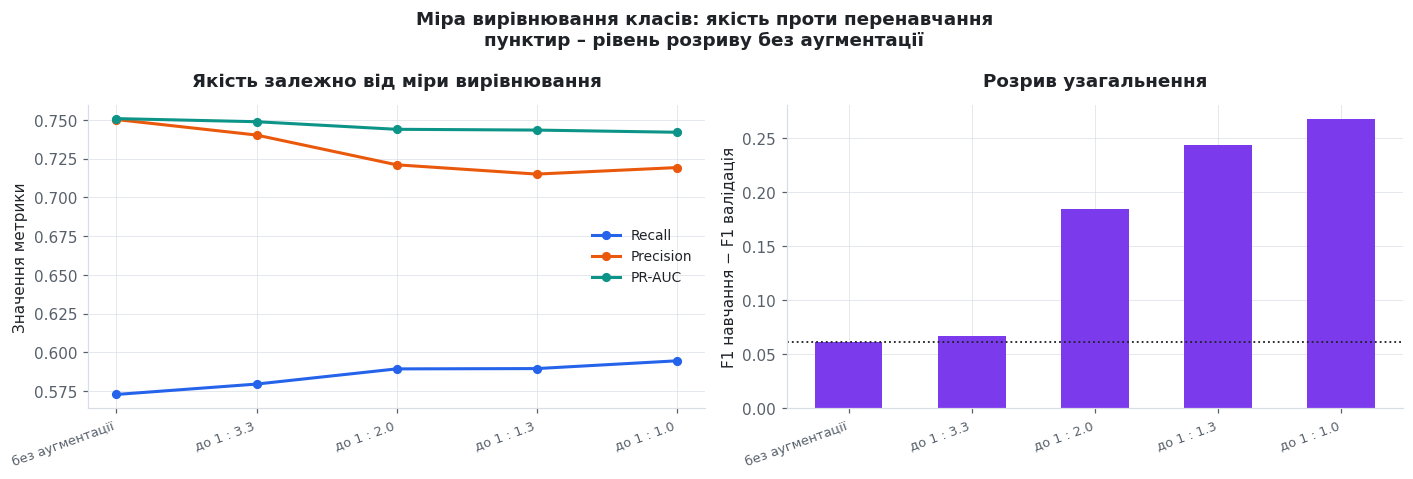

In [33]:
# --- Вплив міри вирівнювання класів на якість і перенавчання ---
strategies = [None, 0.3, 0.5, 0.75, 1.0]   # None – без аугментації
strat_rows = []
# Модель у всіх варіантах та сама, змінюється лише обсяг аугментації –
# отже, різниця метрик пояснюється саме нею.

for s in strategies:
    # sampling_strategy задає відношення обсягу міноритарного класу
    # до мажоритарного після аугментації: 1.0 – повна рівність.
    if s is None:
        Xs, ys, label = B_train, y_train, "без аугментації"
    else:
        sm_s = SMOTE(sampling_strategy=s, k_neighbors=5, random_state=RANDOM_STATE)
        Xs, ys = sm_s.fit_resample(B_train, y_train)
        label = f"до 1 : {1 / s:.1f}"

    mdl = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1,
                                         early_stopping=False, random_state=RANDOM_STATE)
    res, _ = evaluate_model(mdl, Xs, ys, B_valid, y_valid,
                            "Градієнтний бустинг", label)
    # Поруч зберігаємо і якість, і розрив узагальнення: саме їх
    # зіставлення показує, де аугментація починає шкодити.
    strat_rows.append({
        "Вирівнювання": label,
        "Рядків": len(Xs),
        "Синтетичних": len(Xs) - len(B_train),
        "Recall": res["Recall"], "Precision": res["Precision"],
        "F1": res["F1"], "PR-AUC": res["PR-AUC"],
        "Розрив F1": res["Розрив F1"],
    })
    print(f"  {label:<18} – готово")

strat = pd.DataFrame(strat_rows)
display(strat)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(len(strat))

# Ліва панель: три метрики на спільній шкалі – видно, що зростає, а що падає
for k, m in enumerate(["Recall", "Precision", "PR-AUC"]):
    axes[0].plot(x, strat[m], marker="o", markersize=5, color=PALETTE[k], label=m)
axes[0].set_xticks(x)
axes[0].set_xticklabels(strat["Вирівнювання"], rotation=20, ha="right", fontsize=8.5)
axes[0].legend(fontsize=9)
style_axes(axes[0], title="Якість залежно від міри вирівнювання", ylabel="Значення метрики")

# Права панель: розрив узагальнення з лінією рівня без аугментації
axes[1].bar(x, strat["Розрив F1"], 0.55, color=PALETTE[3])
axes[1].set_xticks(x)
axes[1].set_xticklabels(strat["Вирівнювання"], rotation=20, ha="right", fontsize=8.5)
axes[1].axhline(strat["Розрив F1"].iloc[0], color=INK, linestyle=":", linewidth=1.2)
style_axes(axes[1], title="Розрив узагальнення",
           ylabel="F1 навчання − F1 валідація")

fig.suptitle("Міра вирівнювання класів: якість проти перенавчання\n"
             "пунктир – рівень розриву без аугментації",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### Комірка 5.6 – умова перенавчання 3: спотворення калібрування

Оверсемплінг змінює апріорну частоту класів у навчальній вибірці: модель бачить
рівні класи, тоді як у реальності позитивний клас трапляється приблизно вчетверо
рідше. Тому ймовірності на виході систематично **завищуються**.

Формально це не перенавчання, але наслідок той самий: при стандартному порозі 0,5
модель оголошує позитивний клас надто часто, і точність падає. Саме цей механізм,
а не покращення розділової здатності, пояснює зростання Recall після аугментації.

Будуємо **діаграму надійності**: спостереження групуємо за прогнозованою ймовірністю
й порівнюємо середній прогноз із фактичною часткою позитивного класу в групі. Ідеально
відкалібрована модель лягла б на діагональ.

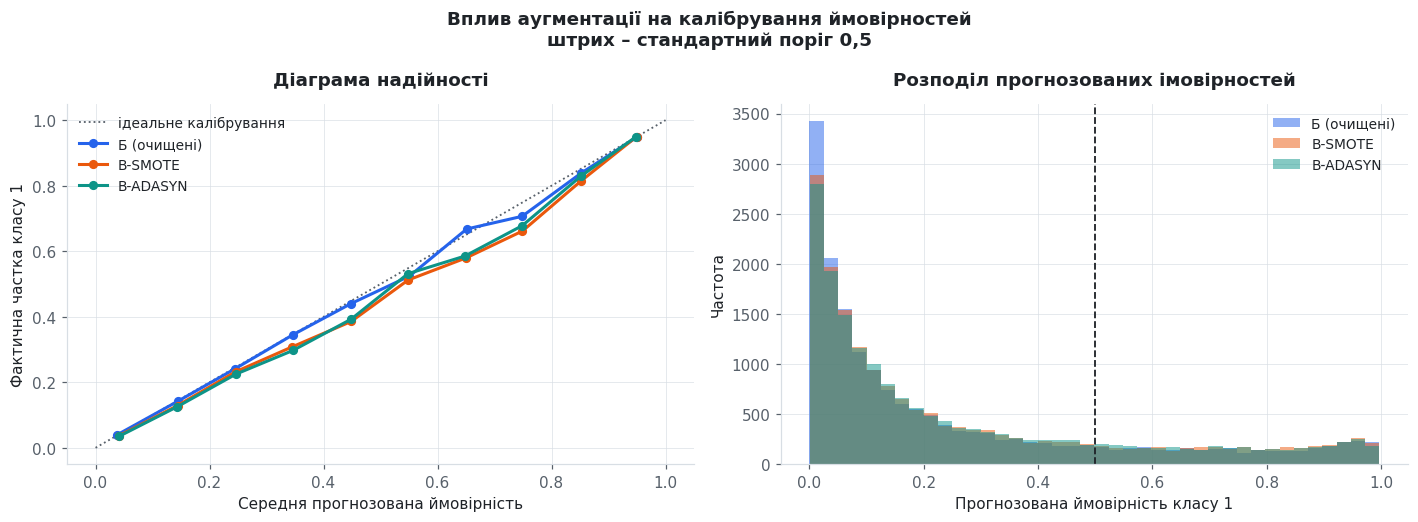

,Сценарій,Середня прогнозована ймовірність,Фактична частка класу 1,Зсув,"Частка прогнозів > 0,5"
0,Б (очищені),0.2414,0.2389,0.0025,0.1824
1,В-SMOTE,0.2584,0.2389,0.0195,0.1975
2,В-ADASYN,0.2590,0.2389,0.0201,0.1968


In [34]:
# --- Калібрування ймовірностей до і після аугментації ---
def reliability(proba, y_true, n_bins=10):
    """Групує спостереження за прогнозованою ймовірністю.

    Повертає середній прогноз і фактичну частку позитивного класу в кожній групі.
    """
    bins = np.linspace(0, 1, n_bins + 1)
    # digitize повертає номер інтервалу, рахуючи з одиниці -> віднімаємо 1
    idx = np.digitize(proba, bins) - 1
    idx = np.clip(idx, 0, n_bins - 1)
    mean_pred, frac_pos, counts = [], [], []
    for b in range(n_bins):
        # Порожній інтервал позначаємо NaN, щоб він не малювався на графіку
        m = idx == b
        if m.sum() == 0:
            mean_pred.append(np.nan); frac_pos.append(np.nan); counts.append(0)
        else:
            mean_pred.append(proba[m].mean())
            frac_pos.append(y_true[m].mean())
            counts.append(int(m.sum()))
    return np.array(mean_pred), np.array(frac_pos), np.array(counts)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Ліва панель: діаграма надійності
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle=":", linewidth=1.2,
             label="ідеальне калібрування")
for k, scen in enumerate(["Б (очищені)", "В-SMOTE", "В-ADASYN"]):
    mp, fp, _ = reliability(proba_store[(scen, "Градієнтний бустинг")], y_valid)
    axes[0].plot(mp, fp, marker="o", markersize=5, color=PALETTE[k], label=scen)
style_axes(axes[0], title="Діаграма надійності",
           xlabel="Середня прогнозована ймовірність",
           ylabel="Фактична частка класу 1")
axes[0].legend(fontsize=9)

# Права панель: розподіл самих прогнозованих імовірностей
for k, scen in enumerate(["Б (очищені)", "В-SMOTE", "В-ADASYN"]):
    axes[1].hist(proba_store[(scen, "Градієнтний бустинг")], bins=40, alpha=.5,
                 color=PALETTE[k], label=scen)
axes[1].axvline(0.5, color=INK, linestyle="--", linewidth=1.2)
style_axes(axes[1], title="Розподіл прогнозованих імовірностей",
           xlabel="Прогнозована ймовірність класу 1", ylabel="Частота")
axes[1].legend(fontsize=9)

fig.suptitle("Вплив аугментації на калібрування ймовірностей\n"
             "штрих – стандартний поріг 0,5",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Числове підтвердження зсуву: наскільки середня прогнозована ймовірність
# відхиляється від фактичної частки позитивного класу.
calib = pd.DataFrame([
    {"Сценарій": scen,
     "Середня прогнозована ймовірність":
         round(float(np.mean(proba_store[(scen, "Градієнтний бустинг")])), 4),
     "Фактична частка класу 1": round(float(y_valid.mean()), 4),
     "Зсув": round(float(np.mean(proba_store[(scen, "Градієнтний бустинг")])
                         - y_valid.mean()), 4),
     "Частка прогнозів > 0,5":
         round(float((proba_store[(scen, "Градієнтний бустинг")] > .5).mean()), 4)}
    for scen in ["Б (очищені)", "В-SMOTE", "В-ADASYN"]
])
display(calib)


### Комірка 5.7 – умова перенавчання 4: взаємодія з гнучкістю моделі

Четвертий механізм стосується не самих даних, а їх поєднання з ємністю моделі.
Синтетичні точки лежать на відрізках між реальними, тобто **всередині** вже зайнятої
класом області. Достатньо гнучка модель здатна провести межу навколо кожного такого
згустку й фактично запам'ятати його.

Перевіряємо це на деревах рішень різної глибини, навчених на тих самих даних
**без** аугментації та **з** нею. Якщо механізм діє, розрив узагальнення на
аугментованих даних має зростати з глибиною швидше.

Дані,SMOTE,без аугментації
Глибина,,
4,0.1816,0.0121
6,0.1868,0.0163
8,0.2026,0.0298
10,0.2305,0.0690
14,0.3016,0.2175
18,0.3786,0.3583


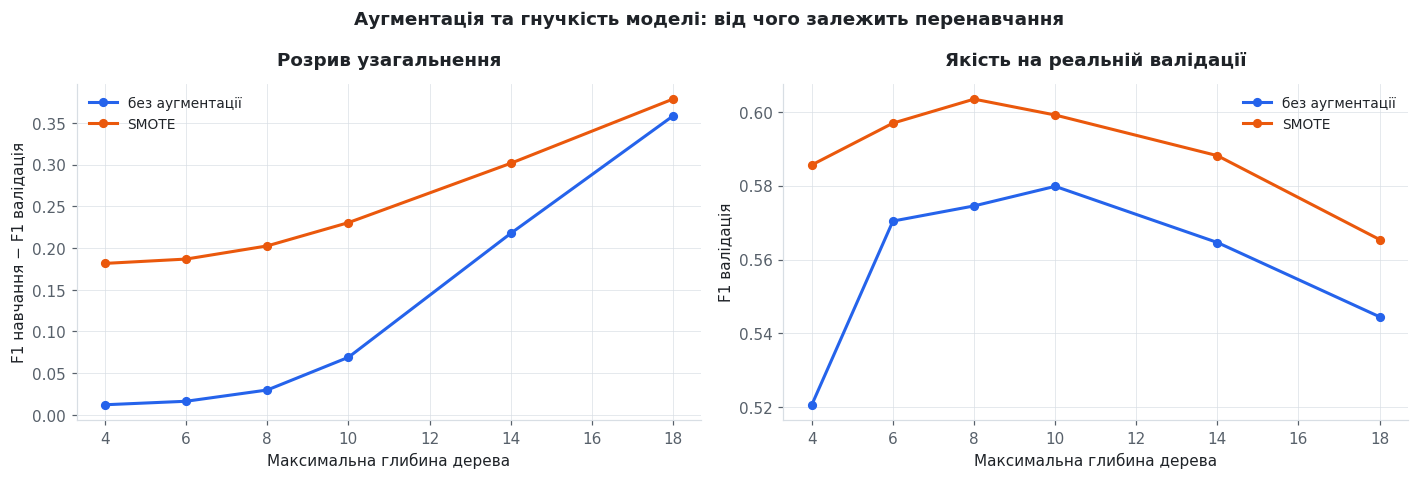

In [35]:
# --- Взаємодія аугментації з гнучкістю моделі ---
depths_i = [4, 6, 8, 10, 14, 18]   # від помірної до надмірної гнучкості
inter_rows = []

# Дерево обрано навмисно: його ємність задається одним зрозумілим
# параметром, тож ефект від глибини не змішується з іншими чинниками.
for d in depths_i:
    for scen, (Xs, ys) in [("без аугментації", (B_train, y_train)),
                           ("SMOTE", (V_sm_train, y_sm_train))]:
        tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
        tree.fit(Xs, ys)
        # F1 на навчанні рахуємо на тій вибірці, на якій модель навчалася
        # (для SMOTE – на аугментованій), бо саме її вона могла запам'ятати.
        f1_tr = f1_score(ys, tree.predict(Xs))
        f1_va = f1_score(y_valid, tree.predict(B_valid))
        inter_rows.append({"Глибина": d, "Дані": scen,
                           "F1 навчання": round(f1_tr, 4),
                           "F1 валідація": round(f1_va, 4),
                           "Розрив": round(f1_tr - f1_va, 4)})

inter = pd.DataFrame(inter_rows)
display(inter.pivot(index="Глибина", columns="Дані", values="Розрив"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for k, scen in enumerate(["без аугментації", "SMOTE"]):
    sub = inter[inter["Дані"] == scen]
    axes[0].plot(sub["Глибина"], sub["Розрив"], marker="o", markersize=5,
                 color=PALETTE[k], label=scen)
    axes[1].plot(sub["Глибина"], sub["F1 валідація"], marker="o", markersize=5,
                 color=PALETTE[k], label=scen)

style_axes(axes[0], title="Розрив узагальнення", xlabel="Максимальна глибина дерева",
           ylabel="F1 навчання − F1 валідація")
style_axes(axes[1], title="Якість на реальній валідації",
           xlabel="Максимальна глибина дерева", ylabel="F1 валідація")
for ax in axes:
    ax.legend(fontsize=9)

fig.suptitle("Аугментація та гнучкість моделі: від чого залежить перенавчання",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


---
# Розділ 6. Підсумковий звіт

**Завдання методички (пункт 6):** сформувати підсумковий звіт про стан даних та
виконані перетворення.

Усі попередні порівняння виконувалися на валідаційній вибірці 2016 року. Тестову
вибірку 2017 року ми не торкалися жодного разу – саме тому вона може слугувати
незалежною перевіркою остаточного вибору.

### Комірка 6.1 – стан даних та виконані перетворення

Перша частина звіту: що саме відбулося з даними на кожному сценарії. Таблиця показує
обсяг, кількість ознак, наявність пропусків і перелік застосованих перетворень.

In [36]:
# --- Звіт про стан даних та виконані перетворення ---
def _state(name, X_tr, y_tr, X_va, transforms):
    """Збирає рядок звіту про одну матрицю ознак.

    Кількість синтетичних рядків визначаємо як перевищення над обсягом
    сценарію Б: усі аугментовані варіанти побудовано саме на ньому.
    """
    return {
        "Сценарій": name,
        "Рядків у навчанні": len(X_tr),
        "Ознак": X_tr.shape[1],
        "Пропусків": int(X_tr.isna().sum().sum() + X_va.isna().sum().sum()),
        "Частка класу 1, %": round(float(np.mean(y_tr)) * 100, 2),
        "Синтетичних рядків": max(0, len(X_tr) - len(B_train)),
        "Перетворення": transforms,
    }

# Перший рядок – сирі дані, для довідки: показує вихідну кількість пропусків,
# які й довелося опрацьовувати на наступних сценаріях.
data_state = pd.DataFrame([
    _state("Сирі дані", df_train[FEATURES], y_train, df_valid[FEATURES],
           "жодних (для довідки)"),
    _state("А (базові)", A_train, y_train, A_valid,
           "медіанна імп'ютація; порядкове кодування"),
    _state("Б (очищені)", B_train, y_train, B_valid,
           "MICE; прапорці MNAR; Target + Frequency + One-Hot + Ordinal; Yeo-Johnson"),
    _state("Б+ (інженерія)", P_train, y_train, P_valid,
           "Б + різниці, взаємодії, циклічний місяць, аномальність, "
           "відхилення від норми станції, поліноми"),
    _state("В-SMOTE", V_sm_train, y_sm_train, B_valid,
           "Б + SMOTE до рівності класів"),
    _state("В-ADASYN", V_ad_train, y_ad_train, B_valid,
           "Б + ADASYN до рівності класів"),
])

pd.set_option("display.max_colwidth", 90)
display(data_state)
pd.reset_option("display.max_colwidth")


,Сценарій,Рядків у навчанні,Ознак,Пропусків,"Частка класу 1, %",Синтетичних рядків,Перетворення
0,Сирі дані,116219,21,290553,22.31,0,жодних (для довідки)
1,А (базові),116219,21,0,22.31,0,медіанна імп'ютація; порядкове кодування
2,Б (очищені),116219,74,0,22.31,0,MICE; прапорці MNAR; Target + Frequency + One-Hot + Ordinal; Yeo-Johnson
3,Б+ (інженерія),116219,106,0,22.31,0,"Б + різниці, взаємодії, циклічний місяць, аномальність, відхилення від норми станції, ..."
4,В-SMOTE,180576,74,0,50.00,64357,Б + SMOTE до рівності класів
5,В-ADASYN,180163,74,0,49.89,63944,Б + ADASYN до рівності класів


### Комірка 6.2 – вибір остаточної конфігурації

Найкращу пару «сценарій × модель» обираємо за **PR-AUC** на валідації. Ця метрика
обрана головною ще в ЛР №1: за дисбалансу 1 : 3,5 Accuracy непридатна, бо тривіальний
класифікатор, який завжди прогнозує відсутність опадів, дає близько 78 % правильних
відповідей за нульової повноти щодо класу, який і становить практичний інтерес.

Сценарії з аугментацією розглядаємо нарівні з рештою: рішення має спиратися на
виміряний результат, а не на очікування.

In [37]:
# --- Вибір остаточної конфігурації за PR-AUC на валідації ---
# Сортуємо всі 15 комбінацій за головною метрикою й дивимося першу десятку
ranking = results.sort_values("PR-AUC", ascending=False).reset_index(drop=True)
display(ranking[["Сценарій", "Модель", "PR-AUC", "F1", "ROC-AUC",
                 "Recall", "Precision", "Розрив F1", "Час, с"]].head(10))

best_row = ranking.iloc[0]
BEST_SCENARIO = best_row["Сценарій"]
BEST_MODEL = best_row["Модель"]

print(f"Остаточний вибір: {BEST_SCENARIO} + {BEST_MODEL}")
print(f"  PR-AUC на валідації: {best_row['PR-AUC']:.4f}")
print(f"  F1 на валідації:     {best_row['F1']:.4f}")
print(f"  Розрив F1:           {best_row['Розрив F1']:.4f}")


,Сценарій,Модель,PR-AUC,F1,ROC-AUC,Recall,Precision,Розрив F1,"Час, с"
0,Б+ (інженерія),Градієнтний бустинг,0.7514,0.6469,0.8844,0.5747,0.7399,0.0793,19.7
1,Б (очищені),Градієнтний бустинг,0.7508,0.6496,0.8834,0.5728,0.7502,0.0610,14.8
2,А (базові),Градієнтний бустинг,0.7475,0.6444,0.8824,0.5661,0.7479,0.0608,4.5
3,В-ADASYN,Градієнтний бустинг,0.7426,0.6515,0.8802,0.5941,0.7213,0.2648,25.8
4,В-SMOTE,Градієнтний бустинг,0.7420,0.6510,0.8791,0.5945,0.7192,0.2674,25.0
5,Б+ (інженерія),Випадковий ліс,0.7268,0.6133,0.8731,0.5233,0.7405,0.3616,138.6
6,Б (очищені),Випадковий ліс,0.7234,0.6109,0.8698,0.5188,0.7429,0.3376,63.9
7,А (базові),Випадковий ліс,0.7231,0.6014,0.8724,0.5037,0.7461,0.3661,56.9
8,В-SMOTE,Випадковий ліс,0.7187,0.6515,0.8715,0.6658,0.6379,0.3435,137.6
9,В-ADASYN,Випадковий ліс,0.7173,0.6569,0.8718,0.6828,0.6328,0.3405,142.7


Остаточний вибір: Б+ (інженерія) + Градієнтний бустинг
  PR-AUC на валідації: 0.7514
  F1 на валідації:     0.6469
  Розрив F1:           0.0793


### Комірка 6.3 – фінальна оцінка на тестовій вибірці 2017 року

Перевіряємо всі три моделі на найкращому сценарії. Тестова вибірка відокремлена від
навчальної не лише випадково, а **в часі**: це найсуворіша з можливих перевірок, бо
модель оцінюється на періоді, якого в навчанні не було взагалі.

Зіставлення метрик на валідації та на тесті показує, наскільки стабільним є результат.
Помітне падіння означало б, що вибір конфігурації підлаштувався під валідацію.

,Модель,F1 (валідація 2016),F1 (тест 2017),PR-AUC (валідація),PR-AUC (тест),ROC-AUC (тест),Accuracy (тест),Precision (тест),Recall (тест),Зміна PR-AUC
0,Логістична регресія,0.6151,0.5742,0.7068,0.6892,0.8662,0.8516,0.7136,0.4804,-0.0176
1,Випадковий ліс,0.6133,0.5888,0.7268,0.7000,0.8730,0.8581,0.7427,0.4878,-0.0268
2,Градієнтний бустинг,0.6469,0.6108,0.7514,0.7234,0.8840,0.8624,0.7431,0.5184,-0.0280


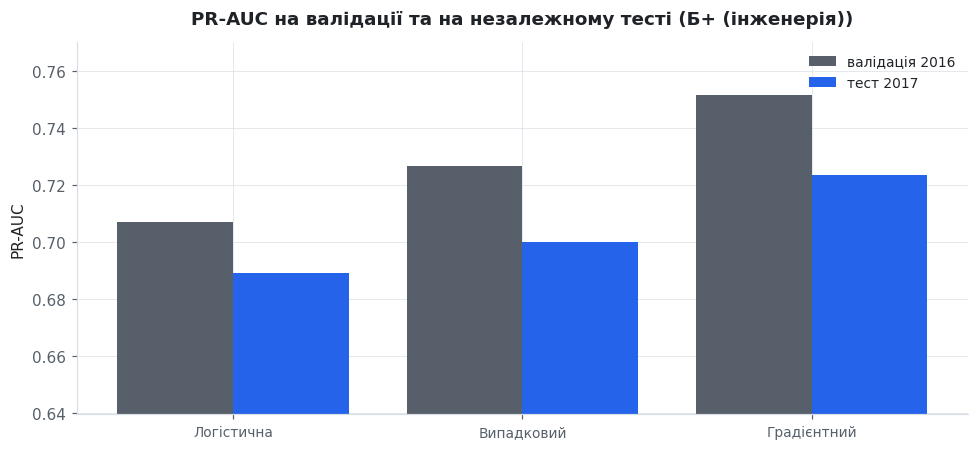

In [38]:
# --- Фінальна оцінка на незалежній тестовій вибірці (2017) ---
# Матриці тестової вибірки відповідають тому самому сценарію.
# Для аугментованих сценаріїв це B_test: аугментація змінює лише
# навчальну вибірку, а набір ознак у них той самий, що й у сценарії Б.
TEST_MATRIX = {"А (базові)": A_test, "Б (очищені)": B_test,
               "Б+ (інженерія)": P_test,
               "В-SMOTE": B_test, "В-ADASYN": B_test}[BEST_SCENARIO]
TRAIN_MATRIX, TRAIN_Y, _, _ = SCENARIOS[BEST_SCENARIO]

final_rows = []
# Перевіряємо всі три моделі, а не лише обрану: якщо падіння на тесті
# буде однаковим для всіх, причина в різниці періодів, а не в підлаштуванні.
for mdl_name, mdl in make_models().items():
    # Навчання – на тих самих даних, що й у порівнянні; оцінка – на тесті
    res, proba_te = evaluate_model(mdl, TRAIN_MATRIX, TRAIN_Y,
                                   TEST_MATRIX, y_test, mdl_name, BEST_SCENARIO)
    # Відповідний рядок із таблиці валідації – для зіставлення
    valid_row = results[(results["Сценарій"] == BEST_SCENARIO) &
                        (results["Модель"] == mdl_name)].iloc[0]
    final_rows.append({
        "Модель": mdl_name,
        "F1 (валідація 2016)": valid_row["F1"],
        "F1 (тест 2017)": res["F1"],
        "PR-AUC (валідація)": valid_row["PR-AUC"],
        "PR-AUC (тест)": res["PR-AUC"],
        "ROC-AUC (тест)": res["ROC-AUC"],
        "Accuracy (тест)": res["Accuracy"],
        "Precision (тест)": res["Precision"],
        "Recall (тест)": res["Recall"],
        "Зміна PR-AUC": round(res["PR-AUC"] - valid_row["PR-AUC"], 4),
    })

final = pd.DataFrame(final_rows)
display(final)

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(final))
ax.bar(x - 0.2, final["PR-AUC (валідація)"], 0.4, color=MUTED, label="валідація 2016")
ax.bar(x + 0.2, final["PR-AUC (тест)"], 0.4, color=PALETTE[0], label="тест 2017")
ax.set_xticks(x)
ax.set_xticklabels([n.split()[0] for n in final["Модель"]], fontsize=9)
# Звужуємо діапазон осі: всі значення лежать у вузькій смузі,
# і від нуля різниця між стовпцями була б непомітна.
lo = min(final["PR-AUC (валідація)"].min(), final["PR-AUC (тест)"].min())
hi = max(final["PR-AUC (валідація)"].max(), final["PR-AUC (тест)"].max())
ax.set_ylim(max(0, lo - (hi - lo) * .8), hi + (hi - lo) * .3)
ax.legend(fontsize=9)
style_axes(ax, title=f"PR-AUC на валідації та на незалежному тесті ({BEST_SCENARIO})",
           ylabel="PR-AUC")
plt.tight_layout()
plt.show()


### Комірка 6.4 – зведена таблиця ключових результатів

Остання таблиця зводить усі числові підсумки роботи в одному місці. Жодне значення
не вписане вручну – усі обчислюються з відповідних змінних, тому таблиця лишається
узгодженою з рештою ноутбука за будь-якого перезапуску.

In [39]:
# --- Зведення ключових числових результатів роботи ---
def _best_of(scen, metric="PR-AUC"):
    """Повертає найкраще значення метрики в межах сценарію та назву моделі."""
    sub = results[results["Сценарій"] == scen]
    r = sub.loc[sub[metric].idxmax()]
    return f"{r[metric]:.4f} ({r['Модель'].split()[0]})"

# Кожне значення обчислюється з відповідної змінної, а не вписується вручну:
# так таблиця залишається узгодженою з рештою ноутбука при будь-якому перезапуску.
summary = pd.DataFrame([
    # --- характеристики даних ---
    ["Обсяг робочої вибірки", f"{len(df):,} × {len(FEATURES)} ознак".replace(",", " ")],
    ["Поділ train / valid / test",
     f"{len(df_train):,} / {len(df_valid):,} / {len(df_test):,}".replace(",", " ")],
    ["Дисбаланс класів",
     f"{y_train.mean() * 100:.2f} % / {(1 - y_train.mean()) * 100:.2f} % "
     f"(1 : {(1 - y_train.mean()) / y_train.mean():.2f})"],
    # --- розмірність матриць за сценаріями ---
    ["Ознак у сценарії А", f"{A_train.shape[1]}"],
    ["Ознак у сценарії Б", f"{B_train.shape[1]}"],
    ["Ознак у сценарії Б+", f"{P_train.shape[1]}"],
    ["Синтетичних рядків (SMOTE)", f"{len(V_sm_train) - len(B_train):,}".replace(",", " ")],
    ["Синтетичних рядків (ADASYN)", f"{len(V_ad_train) - len(B_train):,}".replace(",", " ")],
    # --- результати моделювання ---
    ["Навчено комбінацій", f"{len(results)}"],
    ["Найкращий PR-AUC, сценарій А", _best_of("А (базові)")],
    ["Найкращий PR-AUC, сценарій Б", _best_of("Б (очищені)")],
    ["Найкращий PR-AUC, сценарій Б+", _best_of("Б+ (інженерія)")],
    ["Найкращий PR-AUC, сценарій В-SMOTE", _best_of("В-SMOTE")],
    ["Найкращий PR-AUC, сценарій В-ADASYN", _best_of("В-ADASYN")],
    ["Приріст PR-AUC від очищення (А -> Б)",
     f"{results[results['Сценарій'] == 'Б (очищені)']['PR-AUC'].max() - results[results['Сценарій'] == 'А (базові)']['PR-AUC'].max():+.4f}"],
    ["Приріст PR-AUC від аугментації (Б -> В-SMOTE)",
     f"{results[results['Сценарій'] == 'В-SMOTE']['PR-AUC'].max() - results[results['Сценарій'] == 'Б (очищені)']['PR-AUC'].max():+.4f}"],
    # --- показники перенавчання ---
    ["Найбільший розрив F1", f"{results['Розрив F1'].max():.4f} "
     f"({results.loc[results['Розрив F1'].idxmax(), 'Модель'].split()[0]}, "
     f"{results.loc[results['Розрив F1'].idxmax(), 'Сценарій']})"],
    ["Найменший розрив F1", f"{results['Розрив F1'].min():.4f} "
     f"({results.loc[results['Розрив F1'].idxmin(), 'Модель'].split()[0]}, "
     f"{results.loc[results['Розрив F1'].idxmin(), 'Сценарій']})"],
    ["Оптимальна глибина одного дерева",
     f"{depth_df.loc[depth_df['F1 валідація'].idxmax(), '_d']}"],
    # --- остаточний вибір і перевірка на незалежному тесті ---
    ["Остаточна конфігурація", f"{BEST_SCENARIO} + {BEST_MODEL}"],
    ["PR-AUC на тесті 2017",
     f"{final.loc[final['Модель'] == BEST_MODEL, 'PR-AUC (тест)'].iloc[0]:.4f}"],
    ["F1 на тесті 2017",
     f"{final.loc[final['Модель'] == BEST_MODEL, 'F1 (тест 2017)'].iloc[0]:.4f}"],
], columns=["Показник", "Значення"])

display(summary)


,Показник,Значення
0,Обсяг робочої вибірки,142 193 × 21 ознак
1,Поділ train / valid / test,116 219 / 17 508 / 8 466
2,Дисбаланс класів,22.31 % / 77.69 % (1 : 3.48)
3,Ознак у сценарії А,21
4,Ознак у сценарії Б,74
5,Ознак у сценарії Б+,106
6,Синтетичних рядків (SMOTE),64 357
7,Синтетичних рядків (ADASYN),63 944
8,Навчено комбінацій,15
9,"Найкращий PR-AUC, сценарій А",0.7475 (Градієнтний)


### Комірка 6.5 – збереження артефактів

Зберігаємо порівняльні таблиці та остаточну модель, щоб результати можна було
використати у звіті й у подальших лабораторних роботах без повторного навчання.

In [40]:
# --- Збереження артефактів ---
import joblib

OUT_DIR = Path("lab2_output")
OUT_DIR.mkdir(exist_ok=True)

# Таблиці результатів для звіту: з них зручно брати числа у Word,
# не повертаючись щоразу до ноутбука.
results.to_csv(OUT_DIR / "results_all.csv", index=False)
delta.to_csv(OUT_DIR / "results_augmentation_delta.csv", index=False)
depth_df.drop(columns="_d").to_csv(OUT_DIR / "results_tree_depth.csv", index=False)
timing.to_csv(OUT_DIR / "results_timing.csv", index=False)
final.to_csv(OUT_DIR / "results_test.csv", index=False)
summary.to_csv(OUT_DIR / "summary.csv", index=False)
strat.to_csv(OUT_DIR / "results_sampling_strategy.csv", index=False)
curves.to_csv(OUT_DIR / "results_learning_curves.csv", index=False)

# Остаточна модель, навчена на обраному сценарії.
# Зберігаємо разом із назвами ознак: без них матрицю для нових даних
# неможливо зібрати у правильному порядку стовпців.
best_model_obj = make_models()[BEST_MODEL]
best_model_obj.fit(TRAIN_MATRIX, TRAIN_Y)
joblib.dump({
    "model": best_model_obj,
    "scenario": BEST_SCENARIO,
    "model_name": BEST_MODEL,
    "feature_names": list(TRAIN_MATRIX.columns),
    "random_state": RANDOM_STATE,
}, OUT_DIR / "best_model.joblib")

print(f"Артефакти збережено в теку {OUT_DIR.resolve()}\n")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.name:<36} {f.stat().st_size / 1024:>9,.1f} КБ".replace(",", " "))


Артефакти збережено в теку /content/lab2_output

  best_model.joblib                      1 162.1 КБ
  results_all.csv                            1.7 КБ
  results_augmentation_delta.csv             0.6 КБ
  results_learning_curves.csv                0.6 КБ
  results_sampling_strategy.csv              0.4 КБ
  results_test.csv                           0.5 КБ
  results_timing.csv                         0.9 КБ
  results_tree_depth.csv                     0.4 КБ
  summary.csv                                1.4 КБ
